# **PONTIFICIA UNIVERSIDAD JAVERIANA**
<img src= "https://www.javeriana.edu.co/recursosdb/8091523/8157776/javeriana-web-logo-edu.png/d5eb5e3d-2e95-0d4f-877d-0ed67a254251?t=1676557813805" width = "30%">

## Alisson Garcia Salazar
## ID: 00020562786
## Clase: Procesamiento de Datos a Gran Escala

**Fecha**: 19 de Octubre 2026

**Tema**: Pyspark con Modelos de Machine Learning

**Objetivos:**
- Hacer uso del entorno IDE Python cuaderno: servidor personal
- Usar un dataset de Enfermedades Cardiovasculares
- Desplegar la metodología CRIPS-DM sobre Enfermedades Cardiovasculares
- Explorar las diferentes bibliotecas disponibles
- Identificar la forma de instalación de nuevas bibliotecas, sobre el kernel por defecto
- Hacer documentación extensiva sobre cada tarea/actividad
- Hacer análisis y conclusiones
- Se recomienda subir el cuaderno al repositorio personal

In [1]:
#Librerías
import numpy as np # Operaciones numéricas y vectores
import pandas as pd # Manipulación de datos tabulares, CSV (ej. pd.read_csv)

#Librerías de Apache Spark
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')
import pyspark #API de Spark para python
#Biblioteca para configuraciones y SESSION SPARK
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession, SQLContext # Punto de entrada para usar Spark SQL/DataFrames
from pyspark.sql import functions as F

#Algoritmos de clasificación de Spark ML
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Evaluador de modelos multiclase
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Transformadores de features de Spark ML
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Utilidad para encadenar etapas de ML
from pyspark.ml import Pipeline

#Apache Spark `DenseVector` (necesario para crear la columna features)
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

#Recolector de basura (liberar memoria)
import gc

In [2]:
### Bibliotecas adicionales

#Biblioteca para estadística/inferencia/probabilidades y pintar
import seaborn as sns
#Biblioteca para pintar
import matplotlib.pyplot as plt

In [3]:
###Sesion Spark
configura = SparkConf().set("spark.ui.port","37003")
configura.setAppName("GarciaTallerStroke05")

###Se crea la Sesión Spark
sparkGarcia = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkGarcia, sparkSession=sparkGarcia)

sparkContextoGarcia= sparkGarcia.sparkContext.getOrCreate()

#Se imprime para verificar
print("Quinta Sesión creada el 30 sep 2026")
sparkGarcia

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Quinta Sesión creada el 30 sep 2026


In [4]:
## Revisar los archivos disponibles o datasets
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /

Found 12 items
drwxr-xr-x   - sistemas  supergroup          0 2025-10-31 15:50 /DistriFlipa
drwxrwxrwx   - sistemas  supergroup          0 2026-10-30 08:30 /FAC_Dataset
drwxrwxrwx   - sistemas  supergroup          0 2026-11-11 08:04 /Formatos1055
drwxrwxrwx   - sistemas  supergroup          0 2026-11-08 11:44 /Formatos1255
drwxrwxrwx   - sistemas  supergroup          0 2026-11-12 18:15 /FormatosHPC
drwxr-xr-x   - seguridad supergroup          0 2026-11-14 23:34 /benchmark
drwxr-xr-x   - sistemas  supergroup          0 2026-11-12 12:15 /csv
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 13:23 /json
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 16:56 /parquet
drwxrwxr-x+  - userpm025 supergroup          0 2025-10-25 17:51 /pm25
drwxrwxrwx   - sistemas  supergroup          0 2026-11-13 16:19 /seguridad
drwxr-xr-x   - usuario22 usuario22           0 2026-04-15 15:19 /user22


In [5]:
#Revisar un archivo especifico ej:taxi
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv/taxi

Found 3 items
-rw-r--r--   2 sistemas supergroup      89594 2025-06-18 15:19 /csv/taxi/taxi-etl-input-small.csv
-rw-r--r--   2 sistemas supergroup     278795 2025-06-18 15:26 /csv/taxi/taxi-test.csv
-rw-r--r--   2 sistemas supergroup    1114146 2025-06-18 15:26 /csv/taxi/taxi-train.csv


In [6]:
## Revisar los archivos datasets carpeta csv
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


In [7]:
#Se carga el dataset: stroke_pyspark.csv a la sesión actual de trabajo
url = "hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv"
df00 = sparkGarcia.read.format("csv").option("header","true").load(url)

df00.show(5)

+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender|age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male| 67|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female| 61|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male| 80|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female| 49|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female| 79|           1|            0|         Yes|Self

## CARGAR EL DATASET

In [8]:
#Se observa la carpeta CSV del datalake HADOOP
#La idea es usar el dataset desde Hadoop para no traaerlo de manera local: siempre de forma remota
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


### **1. Diágnostico y Tratamiento de Datos**

- Cambio de nombres de columnas (features)
- Tipos y coherencia de datos
- Identificación y tratamiento de datos nulos/atipicos
- Estadística de los datos
- Tratamiento de columnas categóricas

In [9]:
## Cambio de nombres de columnas (features)
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [10]:
nuevosNombres = ['id','Genero','Edad','Hipertension',
                 'EnfCardiaco','Casado','TipoTrabajo',
                 'TipoResidencia','PromNivelGlucosa', 'BMI',
                 'Fumador','Derrame']
### Se cambian por los nuevos nombres
df01 = df00
for antes,nuevo in zip(df00.columns, nuevosNombres):
    df01 = df01.withColumnRenamed(antes,nuevo)
df01.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame']

In [11]:
df01.show(5)

[Stage 2:>                                                          (0 + 1) / 1]

+-----+------+----+------------+-----------+------+-------------+--------------+----------------+----+---------------+-------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|Casado|  TipoTrabajo|TipoResidencia|PromNivelGlucosa| BMI|        Fumador|Derrame|
+-----+------+----+------------+-----------+------+-------------+--------------+----------------+----+---------------+-------+
| 9046|  Male|  67|           0|          1|   Yes|      Private|         Urban|          228.69|36.6|formerly smoked|      1|
|51676|Female|  61|           0|          0|   Yes|Self-employed|         Rural|          202.21| N/A|   never smoked|      1|
|31112|  Male|  80|           0|          1|   Yes|      Private|         Rural|          105.92|32.5|   never smoked|      1|
|60182|Female|  49|           0|          0|   Yes|      Private|         Urban|          171.23|34.4|         smokes|      1|
| 1665|Female|  79|           1|          0|   Yes|Self-employed|         Rural|          174.12|  24|   never 

#### Escribir un párrafo de al menos 3 oraciones que justifiquen la salida de la variable ID en el estudio
La variable ID corresponde a un código numérico asignado a cada paciente con el propósito de diferenciarlo e identificarlo dentro de la base de datos. Sin embargo, esta variable no contiene información relacionada con las características personales, clínicas o factores de riesgo que puedan influir en la probabilidad de sufrir un derrame cerebral. Además, al tratarse de un identificador único, sus valores no representan una relación de orden, magnitud o comportamiento que pueda ser interpretada por un modelo de análisis. Por lo tanto, mantener esta variable podría generar ruido o aportar información irrelevante durante el entrenamiento del modelo, sin contribuir a la identificación de patrones significativos. En consecuencia, se considera conveniente eliminarla del conjunto de datos para trabajar únicamente con aquellas variables que sí proporcionan información útil para el análisis y la predicción del riesgo de sufrir un derrame cerebral.

In [12]:
# Tipos de Datos
df01.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Hipertension: string (nullable = true)
 |-- EnfCardiaco: string (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromNivelGlucosa: string (nullable = true)
 |-- BMI: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: string (nullable = true)



In [13]:
###Edad: string se cambia a entero
df02 = df01.withColumn("Edad", df01.Edad.cast("int"))
### Hipertension: string, se castea a entero
df02 = df02.withColumn("Hipertension", df01.Hipertension.cast("int"))
### EnfCardiaco: string, se castea a entero
df02 = df02.withColumn("EnfCardiaco", df01.EnfCardiaco.cast("int"))
### BMI: string, se castea a double
df02 = df02.withColumn("BMI", df01.BMI.cast("double"))
### Derrame: string, se castea a entero
df02 = df02.withColumn("Derrame", df01.Derrame.cast("int"))
### PromNivelGlucosa: string, se castea a double
df02 = df02.withColumn("PromNivelGlucosa", df01.PromNivelGlucosa.cast("double"))
### Genero: string, se castea a string
df02 = df02.withColumn("Genero", df01.Genero.cast("string"))

In [14]:
df02.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [15]:
## Se crea una tabla para la identificación y tratamiento de datos nulos/atípicos
df02.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|Casado|TipoTrabajo|TipoResidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|               0|201|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



In [16]:
##Auxiliar
df02.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame']

In [17]:
df02Aux = df02['id','Edad','Hipertension','EnfCardiaco',
 'Casado', 'TipoTrabajo','TipoResidencia','PromNivelGlucosa',
 'BMI','Fumador','Derrame']
df02Aux.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02Aux.columns]).show()

+---+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Edad|Hipertension|EnfCardiaco|Casado|TipoTrabajo|TipoResidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|   0|           0|          0|     0|          0|             0|               0|201|      0|      0|
+---+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



## Observación y tratamiento de variables categoricas

-Género

-Casado

-Tipo de trabajo

-Tipo de resistencia

-Fumador

In [18]:
#Cuales generos hay en el dataset?
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



In [19]:
#Se descarta el valor "other" en la variable genero
df02 = df02.where("Genero <> 'Other'")

##Se verifica que ya no esta "Other"
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
|  Male| 2115|
+------+-----+



In [20]:
df02.groupby(['Casado']).count().show()

+------+-----+
|Casado|count|
+------+-----+
|    No| 1756|
|   Yes| 3353|
+------+-----+



In [21]:
df02.groupby(['TipoTrabajo']).count().show()

+-------------+-----+
|  TipoTrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2924|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



In [22]:
df02.groupby(['TipoResidencia']).count().show()

+--------------+-----+
|TipoResidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2513|
+--------------+-----+



In [23]:
df02.groupby(['Fumador']).count().show()

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  884|
+---------------+-----+



## Variable IMC
SE OBSERVA QUE EXISTE 201 DATOS NULOS. Para no eliminar de tajada el procentaje de nulos en IMC por em promedio
El promedio sera discriminado por Genero y ranod de edades
Un porcentaje significativo es mayor a 6

In [24]:
nulosBMI = (201/df02.count())*100
print(f"el porcentaje de nulos es = { nulosBMI} %")

el porcentaje de nulos es = 3.9342337052260716 %


In [25]:
#para el 4% de datos de BMI, se ajusta para no eliminarlos.
#se saca el promedio de BMI para cambiarlos
#El promedio se hara por edades y por genero
#La estratificaion ser hará por décadas

In [26]:
#promedio de BMI por female y cada 10 años
avg10F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") <= 10)).select(F.mean(F.col("BMI"))).collect()
avg20F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 10) & (F.col("Edad") <= 20 )).select(F.mean(F.col("BMI"))).collect()
avg30F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 20) & (F.col("Edad") <= 30 )).select(F.mean(F.col("BMI"))).collect()
avg40F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 30) & (F.col("Edad") <= 40 )).select(F.mean(F.col("BMI"))).collect()
avg50F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 40) & (F.col("Edad") <= 50 )).select(F.mean(F.col("BMI"))).collect()
avg60F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 50) & (F.col("Edad") <= 60 )).select(F.mean(F.col("BMI"))).collect()
avg70F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 60) & (F.col("Edad") <= 70 )).select(F.mean(F.col("BMI"))).collect()
avg80F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 70) & (F.col("Edad") <= 80 )).select(F.mean(F.col("BMI"))).collect()
avg90F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 80) & (F.col("Edad") <= 90 )).select(F.mean(F.col("BMI"))).collect()
avg100F = df02.where((F.col("Genero") == F.lit("Female")) & (F.col ("Edad") > 90)).select(F.mean(F.col("BMI"))).collect()

In [27]:
#Se imprime los promedios femeninos
print(f"Promedio de 10 años feminas = {round(avg10F[0][0],2)} BMI")
print(f"Promedio de 20 años feminas = {round(avg20F[0][0],2)} BMI")
print(f"Promedio de 30 años feminas = {round(avg30F[0][0],2)} BMI")
print(f"Promedio de 40 años feminas = {round(avg40F[0][0],2)} BMI")
print(f"Promedio de 50 años feminas = {round(avg50F[0][0],2)} BMI")
print(f"Promedio de 60 años feminas = {round(avg60F[0][0],2)} BMI")
print(f"Promedio de 70 años feminas = {round(avg70F[0][0],2)} BMI")
print(f"Promedio de 80 años feminas = {round(avg80F[0][0],2)} BMI")
print(f"Promedio de 90 años feminas = {round(avg90F[0][0],2)} BMI")



Promedio de 10 años feminas = 18.72 BMI
Promedio de 20 años feminas = 25.52 BMI
Promedio de 30 años feminas = 28.64 BMI
Promedio de 40 años feminas = 31.17 BMI
Promedio de 50 años feminas = 30.94 BMI
Promedio de 60 años feminas = 31.92 BMI
Promedio de 70 años feminas = 30.72 BMI
Promedio de 80 años feminas = 29.23 BMI
Promedio de 90 años feminas = 28.1 BMI


In [28]:
#Promedio de BMI por Male cada 10 años
avg10M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") <= 10)).select(F.mean(F.col("BMI"))).collect()
avg20M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 10) & (F.col("Edad") <= 20 )).select(F.mean(F.col("BMI"))).collect()
avg30M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 20) & (F.col("Edad") <= 30 )).select(F.mean(F.col("BMI"))).collect()
avg40M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 30) & (F.col("Edad") <= 40 )).select(F.mean(F.col("BMI"))).collect()
avg50M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 40) & (F.col("Edad") <= 50 )).select(F.mean(F.col("BMI"))).collect()
avg60M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 50) & (F.col("Edad") <= 60 )).select(F.mean(F.col("BMI"))).collect()
avg70M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 60) & (F.col("Edad") <= 70 )).select(F.mean(F.col("BMI"))).collect()
avg80M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 70) & (F.col("Edad") <= 80 )).select(F.mean(F.col("BMI"))).collect()
avg90M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 80) & (F.col("Edad") <= 90 )).select(F.mean(F.col("BMI"))).collect()
avg100M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col ("Edad") > 90)).select(F.mean(F.col("BMI"))).collect()

In [29]:
#Se imprime los promedios masculinos
print(f"Promedio de 10 años male = {round(avg10M[0][0],2)} BMI")
print(f"Promedio de 20 años male = {round(avg20M[0][0],2)} BMI")
print(f"Promedio de 30 años male = {round(avg30M[0][0],2)} BMI")
print(f"Promedio de 40 años male = {round(avg40M[0][0],2)} BMI")
print(f"Promedio de 50 años male = {round(avg50M[0][0],2)} BMI")
print(f"Promedio de 60 años male = {round(avg60M[0][0],2)} BMI")
print(f"Promedio de 70 años male = {round(avg70M[0][0],2)} BMI")
print(f"Promedio de 80 años male = {round(avg80M[0][0],2)} BMI")
print(f"Promedio de 90 años male = {round(avg90M[0][0],2)} BMI")

Promedio de 10 años male = 19.1 BMI
Promedio de 20 años male = 25.25 BMI
Promedio de 30 años male = 28.31 BMI
Promedio de 40 años male = 31.33 BMI
Promedio de 50 años male = 32.21 BMI
Promedio de 60 años male = 31.85 BMI
Promedio de 70 años male = 31.28 BMI
Promedio de 80 años male = 29.0 BMI
Promedio de 90 años male = 27.81 BMI


Se reemplazan los valores nulos de la variable IMC, por los promedios correspondientes

In [30]:
df03 = df02.withColumn("BMI", F.when((df02["Genero"] == 'Female') & (df02["BMI"].isNull() & (df02["Edad"] < 10)), round(avg10F[0][0],2)).otherwise(df02["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 20)), round(avg20F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 30)), round(avg30F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 40)), round(avg40F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 50)), round(avg50F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 60)), round(avg60F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 70)), round(avg70F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 80)), round(avg80F[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] < 90)), round(avg90F[0][0],2)).otherwise(df03["BMI"]))

In [31]:
df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|Casado|TipoTrabajo|TipoResidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|               0|104|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



In [32]:
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 10)), round(avg10M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 20)), round(avg20M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 30)), round(avg30M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 40)), round(avg40M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 50)), round(avg50M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 60)), round(avg60M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 70)), round(avg70M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 80)), round(avg80M[0][0],2)).otherwise(df03["BMI"]))

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] < 90)), round(avg90M[0][0],2)).otherwise(df03["BMI"]))

In [33]:
df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|Casado|TipoTrabajo|TipoResidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|               0|  0|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



### **Información general del objeto Dataframe PYSpark**

In [34]:
df03.describe().show()

26/11/16 10:14:08 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 96:>                                                         (0 + 1) / 1]

+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+------------------+-----------------+-------+-------------------+
|summary|                id|Genero|             Edad|       Hipertension|        EnfCardiaco|Casado|TipoTrabajo|TipoResidencia|  PromNivelGlucosa|              BMI|Fumador|            Derrame|
+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+------------------+-----------------+-------+-------------------+
|  count|              5109|  5109|             5109|               5109|               5109|  5109|       5109|          5109|              5109|             5109|   5109|               5109|
|   mean| 36513.98551575651|  NULL|43.21863378351928|0.09747504403992954| 0.0540223135642983|  NULL|       NULL|          NULL|106.14039929536098|28.91823253082795|   NULL|0.04873752201996477|
| stddev|21162.008804347086|  NULL|

## Gráfica de los datos

In [35]:
##Para usar Seaborn se hacer el cambio a objeto Pandas
datosIcutus = df03.toPandas()

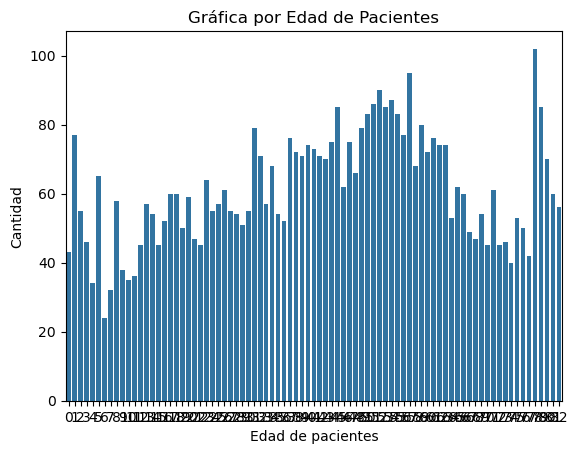

In [36]:
sns.countplot(x = 'Edad' , data = datosIcutus)
plt.title("Gráfica por Edad de Pacientes")
plt.xlabel("Edad de pacientes")
plt.ylabel("Cantidad")
plt.show()

La gráfica permite observar cómo se distribuyen los pacientes entre las diferentes edades. En el conjunto de datos se registran personas entre 0 y 82 años, con una edad promedio de 43,22 años. Esto indica que la muestra incluye tanto población infantil como adulta y de edad avanzada, lo que permite estudiar diferencias entre grupos de edad. 

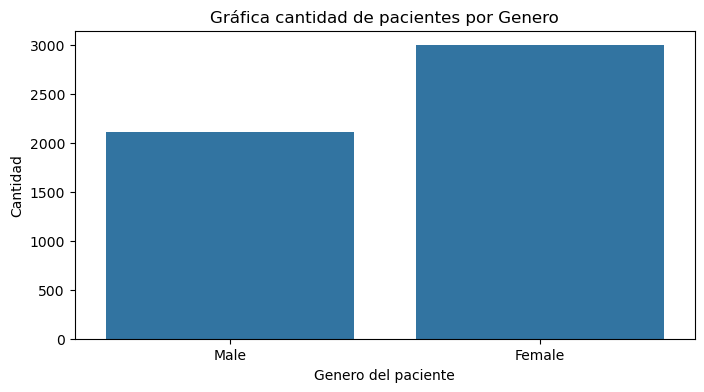

In [37]:
## Gráfica de camtidad por Género
plt.figure(figsize=(8,4))
sns.countplot(x = 'Genero' , data = datosIcutus)
plt.title("Gráfica cantidad de pacientes por Genero")
plt.xlabel("Genero del paciente")
plt.ylabel("Cantidad")
plt.show()


En el conjunto de datos se encontraron 2.994 mujeres y 2.115 hombres, después de excluir el registro clasificado como Other. Las mujeres representan aproximadamente el 58,60 % de los 5.109 pacientes, mientras que los hombres representan el 41,40 %. Por lo tanto, existe una mayor participación femenina en la muestra. Esta diferencia debe considerarse al comparar los casos de derrame entre géneros, porque las cantidades totales no son iguales.

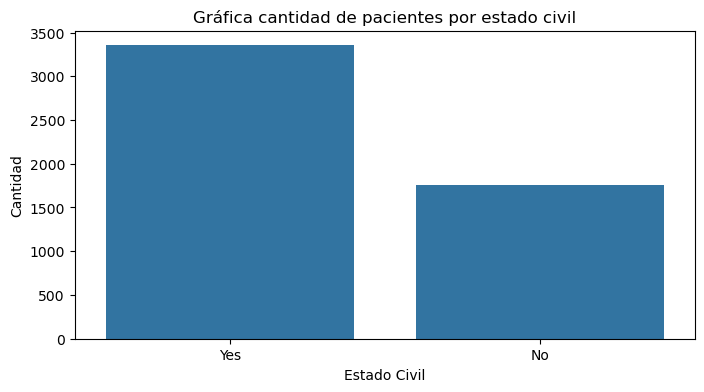

In [38]:
## Gráfica de camtidad por Estado Civil
plt.figure(figsize=(8,4))
sns.countplot(x = 'Casado' , data = datosIcutus)
plt.title("Gráfica cantidad de pacientes por estado civil")
plt.xlabel("Estado Civil")
plt.ylabel("Cantidad")
plt.show()

Se observa que 3.353 pacientes pertenecen a la categoría Yes, mientras que 1.756 pertenecen a No. Esto corresponde aproximadamente al 65,63 % y 34,37 % de la muestra, respectivamente. La mayor parte de los pacientes registra un antecedente de matrimonio. Sin embargo, esta distribución no permite afirmar que el estado civil tenga una relación directa con la presencia de derrame cerebral.

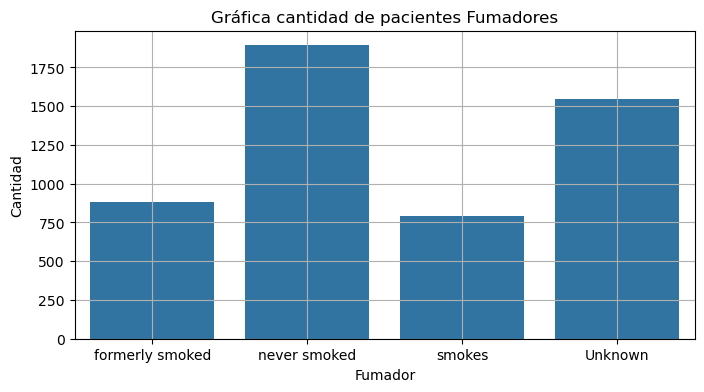

In [39]:
## Gráfica de camtidad por Tipo de Fumador
plt.figure(figsize=(8,4))
sns.countplot(x = 'Fumador' , data = datosIcutus)
plt.title("Gráfica cantidad de pacientes Fumadores")
plt.xlabel("Fumador")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

La categoría más frecuente es never smoked, con 1.892 pacientes, seguida de Unknown, con 1.544. Además, hay 884 pacientes que fumaron anteriormente y 789 que fuman actualmente. Es importante destacar que aproximadamente el 30,22 % de los registros tiene información desconocida sobre el hábito de fumar. Esta cantidad limita la interpretación de la variable, ya que no se conoce el historial de consumo de una parte considerable de la muestra.

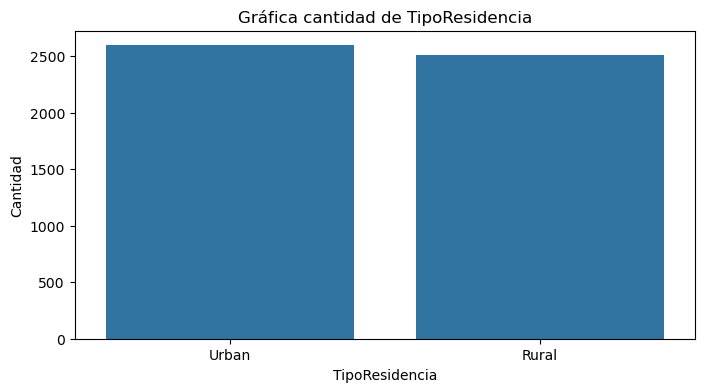

In [40]:
## Gráfica de camtidad por Tipo de residencia
plt.figure(figsize=(8,4))
sns.countplot(x = 'TipoResidencia' , data = datosIcutus)
plt.title("Gráfica cantidad de TipoResidencia")
plt.xlabel("TipoResidencia")
plt.ylabel("Cantidad")
plt.show()

La distribución de pacientes por residencia es bastante equilibrada: 2.596 viven en zonas urbanas y 2.513 en zonas rurales. La diferencia es de apenas 83 registros, por lo que ambos grupos tienen una representación similar en el conjunto de datos. 

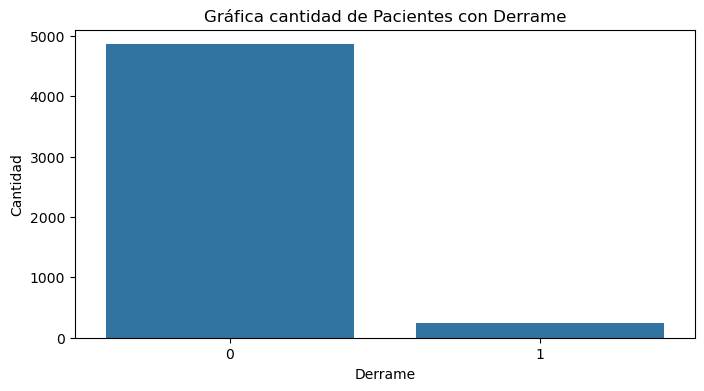

In [41]:
## Gráfica de camtidad por Derrame
plt.figure(figsize=(8,4))
sns.countplot(x = 'Derrame' , data = datosIcutus)
plt.title("Gráfica cantidad de Pacientes con Derrame")
plt.xlabel("Derrame")
plt.ylabel("Cantidad")
plt.show()

###para cada grafica debe haber analisis

De los 5.109 pacientes, 249 presentaron un derrame cerebral y 4.860 no lo presentaron. Esto significa que únicamente el 4,87 % de los registros corresponde a casos positivos, frente al 95,13 % de casos negativos. Se identifica así un desbalance importante en la variable objetivo, que puede llevar a que los modelos aprendan principalmente a reconocer pacientes sin derrame y obtengan valores altos de exactitud sin identificar los casos positivos.

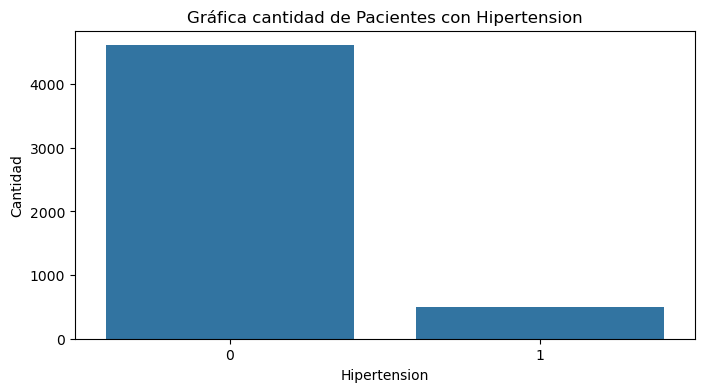

In [42]:
## Gráfica de camtidad por Hipertension
plt.figure(figsize=(8,4))
sns.countplot(x = 'Hipertension' , data = datosIcutus)
plt.title("Gráfica cantidad de Pacientes con Hipertension")
plt.xlabel("Hipertension")
plt.ylabel("Cantidad")
plt.show()

El 9,75 % de los pacientes registra hipertensión, mientras que aproximadamente el 90,25 % no presenta esta condición. Por lo tanto, la hipertensión es una característica minoritaria dentro de la muestra. 

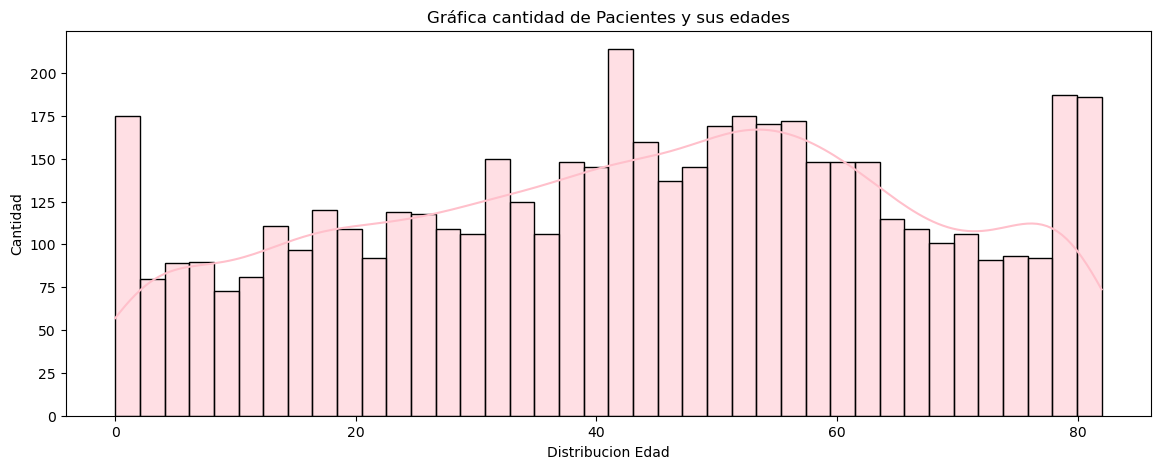

In [43]:
##Se requiere un grafico por edades
plt.figure(figsize=(14,5))
sns.histplot(data=datosIcutus , x= 'Edad', bins =40, kde= True, color ='Pink')
plt.title("Gráfica cantidad de Pacientes y sus edades")
plt.xlabel("Distribucion Edad")
plt.ylabel("Cantidad")
plt.show()

La distribución de edades muestra una distribucion variada. Esto es importante para el estudio porque la presencia de derrame puede variar entre los distintos grupos de edad y conviene analizarla posteriormente utilizando la variable objetivo.

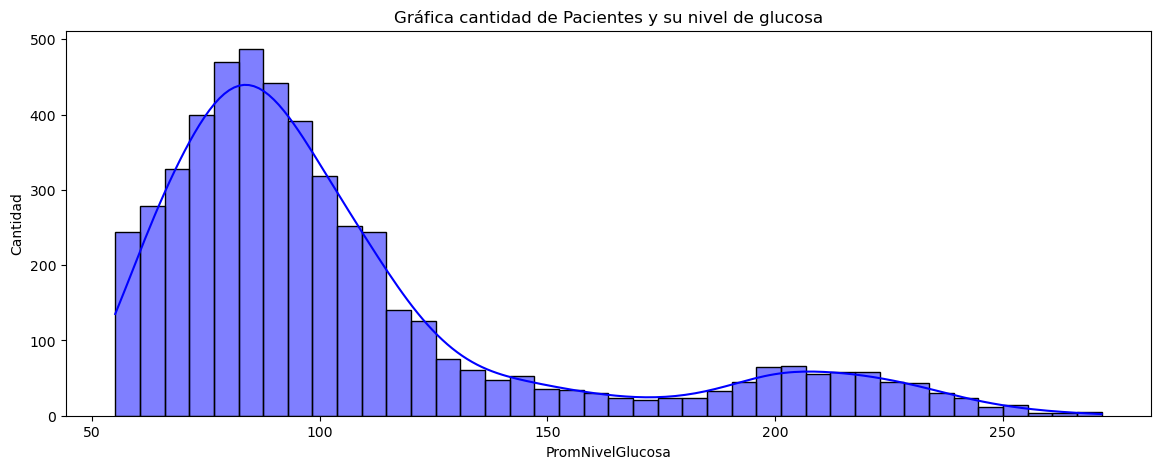

In [44]:
##Se requiere un grafico por nivel de glucosa
plt.figure(figsize=(14,5))
sns.histplot(data=datosIcutus , x= 'PromNivelGlucosa', bins =40, kde= True, color ='blue')
plt.title("Gráfica cantidad de Pacientes y su nivel de glucosa")
plt.xlabel("PromNivelGlucosa")
plt.ylabel("Cantidad")
plt.show()

La distribución presenta una concentración importante en los valores más bajos y una prolongación hacia valores elevados. Esto indica que existen pacientes con niveles de glucosa considerablemente superiores al promedio.

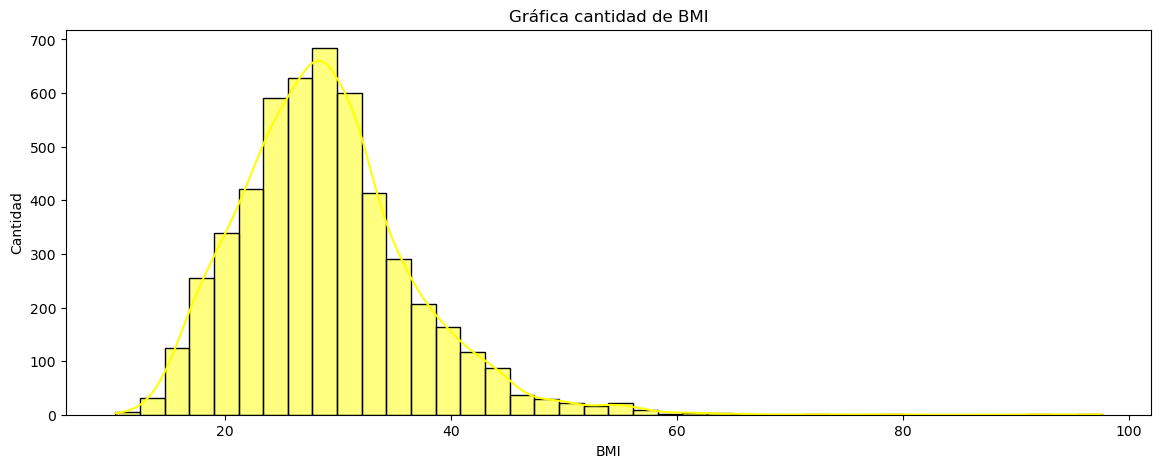

In [45]:
##Se requiere un grafico por BMI
plt.figure(figsize=(14,5))
sns.histplot(data=datosIcutus , x= 'BMI', bins =40, kde= True, color ='yellow')
plt.title("Gráfica cantidad de BMI")
plt.xlabel("BMI")
plt.ylabel("Cantidad")
plt.show()
##revisar graficas seaborn en google

El índice de masa corporal presenta un promedio de 28,92. Aunque una parte importante de los pacientes se concentra alrededor de los valores centrales, también se observan valores elevados, llegando hasta 97,6. Esto evidencia una distribución con valores extremos que pueden influir en el análisis. Además, debe recordarse que algunos datos faltantes de BMI fueron reemplazados previamente por promedios calculados durante la preparación del dataset.

<Figure size 1700x500 with 0 Axes>

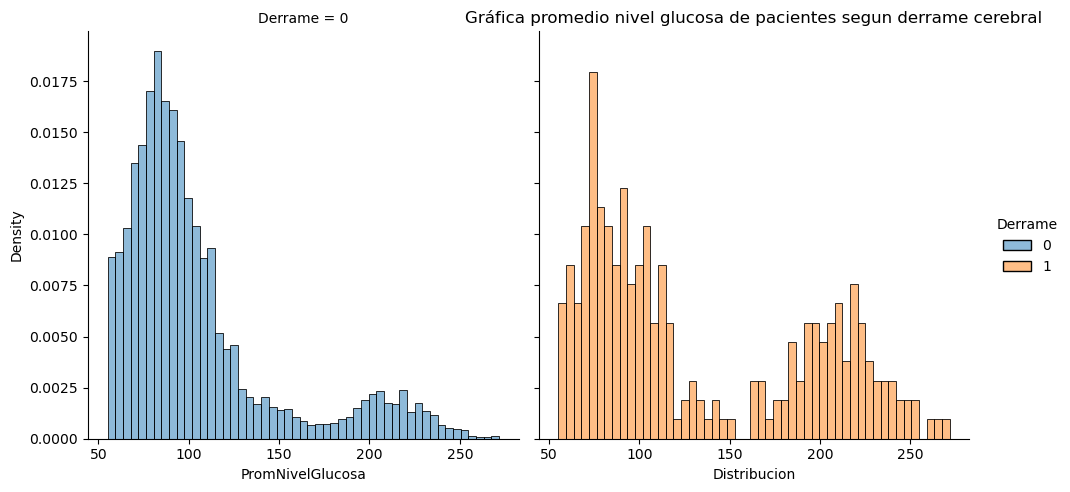

In [46]:
#Se requier una grafica de promedio de nivel de glucosa segun el derrame cerebral
plt.figure(figsize=(17,5))
sns.displot(data = datosIcutus, x= 'PromNivelGlucosa' , hue = 'Derrame', col ='Derrame' , stat ='density' , common_norm = False)
plt.title("Gráfica promedio nivel glucosa de pacientes segun derrame cerebral")
plt.xlabel("Distribucion")
plt.ylabel("Cantidad")
plt.show()

Estas gráficas permiten comparar cómo se distribuye la glucosa en pacientes con y sin derrame cerebral. Las distribuciones se superponen, lo que indica que no existe una separación completa entre los dos grupos utilizando solamente esta variable. Aunque pueden presentarse diferencias en la concentración de valores elevados, la glucosa por sí sola no permite identificar con certeza si un paciente presentó un derrame.

<Figure size 1700x500 with 0 Axes>

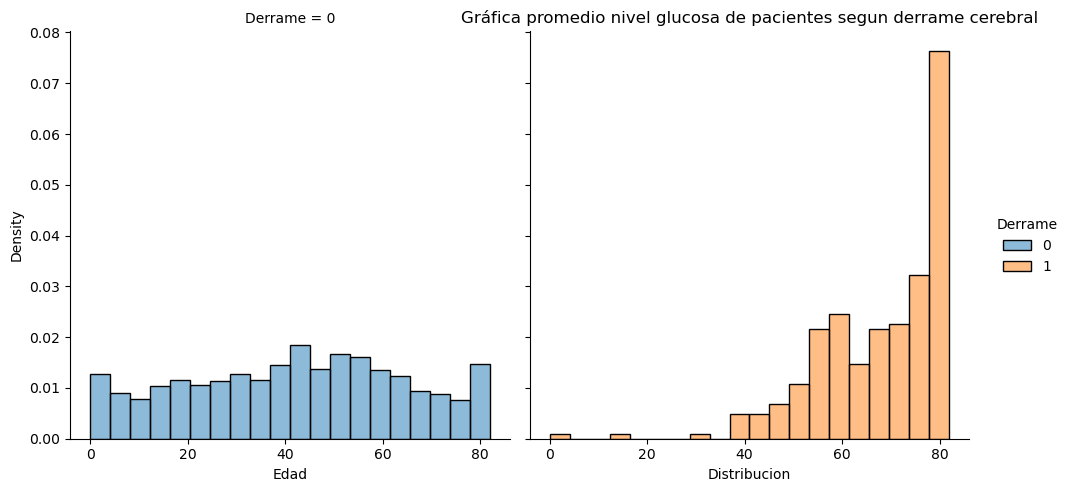

In [47]:
#Se requier una grafica de promedio de nivel de glucosa segun el derrame cerebral
plt.figure(figsize=(17,5))
sns.displot(data = datosIcutus, x= 'Edad' , hue = 'Derrame', col ='Derrame' , stat ='density' , common_norm = False)
plt.title("Gráfica promedio nivel glucosa de pacientes segun derrame cerebral")
plt.xlabel("Distribucion")
plt.ylabel("Cantidad")
plt.show()

Al comparar las edades según la presencia de derrame, se observa que los casos positivos se concentran principalmente en edades más avanzadas, mientras que los pacientes sin derrame abarcan un rango de edades mucho más amplio. Este comportamiento sugiere que la edad es una variable relevante para diferenciar ambos grupos. Sin embargo, también existen pacientes mayores sin derrame, por lo que no constituye una característica suficiente para predecir el evento de manera individual.

<Figure size 1700x500 with 0 Axes>

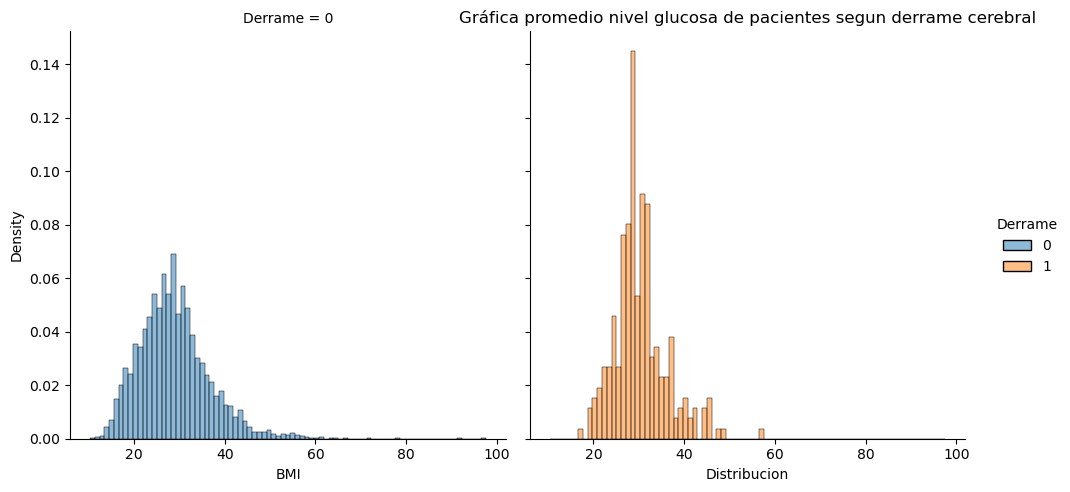

In [48]:
#Se requier una grafica de promedio de nivel de glucosa segun el derrame cerebral
plt.figure(figsize=(17,5))
sns.displot(data = datosIcutus, x= 'BMI' , hue = 'Derrame', col ='Derrame' , stat ='density' , common_norm = False)
plt.title("Gráfica promedio nivel glucosa de pacientes segun derrame cerebral")
plt.xlabel("Distribucion")
plt.ylabel("Cantidad")
plt.show()

Las distribuciones del BMI de pacientes con y sin derrame presentan un solapamiento importante. Esto significa que los valores de índice de masa corporal pueden ser similares en ambos grupos. Aunque existen diferencias individuales y algunos valores extremos, no se observa una separación evidente que permita utilizar únicamente el BMI para distinguir a los pacientes con derrame.

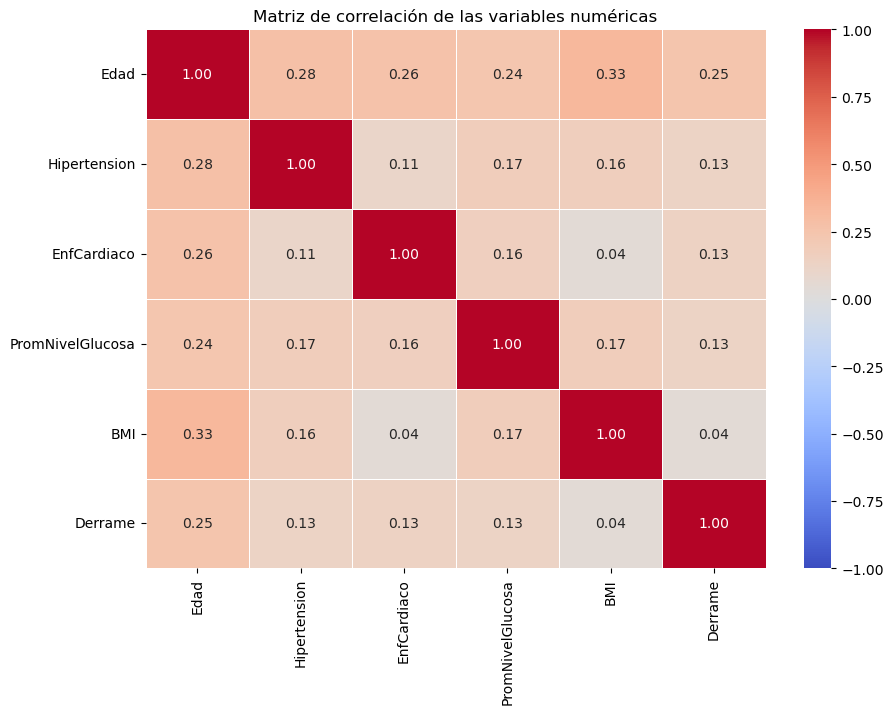

In [49]:
# Seleccionar únicamente variables numéricas y excluir el ID
variables_corr = datosIcutus[
    ['Edad', 'Hipertension', 'EnfCardiaco',
     'PromNivelGlucosa', 'BMI', 'Derrame']
]

# Calcular correlaciones
matriz_corr = variables_corr.corr()

plt.figure(figsize=(10,7))
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación de las variables numéricas')
plt.show()

La matriz permite identificar asociaciones lineales entre las variables numéricas y la presencia de derrame. La edad destaca como una variable que conviene examinar con mayor atención, mientras que las asociaciones más débiles muestran que no todas las características tienen una relación lineal clara con el evento. 

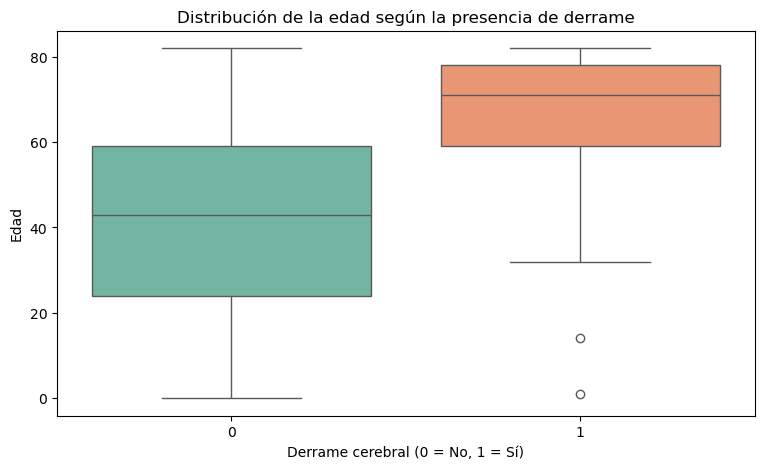

In [50]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=datosIcutus,
    x='Derrame',
    y='Edad',
    hue='Derrame',
    palette='Set2',
    legend=False
)

plt.title('Distribución de la edad según la presencia de derrame')
plt.xlabel('Derrame cerebral (0 = No, 1 = Sí)')
plt.ylabel('Edad')
plt.show()

El diagrama de caja permite observar diferencias en la posición central y la dispersión de las edades entre ambos grupos. Los pacientes con derrame tienden a presentar edades más elevadas, lo que refuerza la relevancia de esta variable.

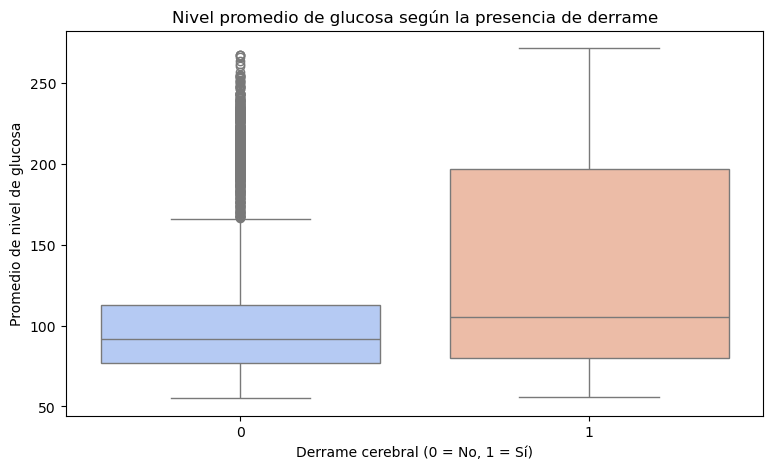

In [51]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=datosIcutus,
    x='Derrame',
    y='PromNivelGlucosa',
    hue='Derrame',
    palette='coolwarm',
    legend=False
)

plt.title('Nivel promedio de glucosa según la presencia de derrame')
plt.xlabel('Derrame cerebral (0 = No, 1 = Sí)')
plt.ylabel('Promedio de nivel de glucosa')
plt.show()

La distribución de glucosa presenta variabilidad en ambos grupos, con valores altos que se alejan de la concentración principal. La superposición de los valores indica que un nivel determinado de glucosa puede encontrarse tanto en pacientes con derrame como en aquellos sin derrame. 

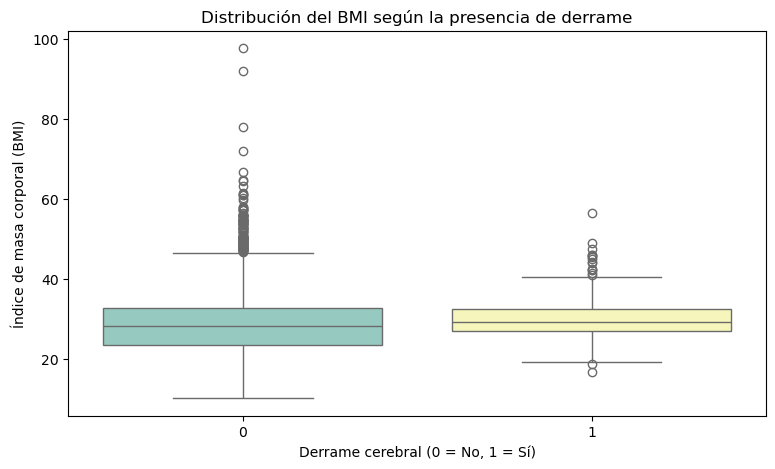

In [52]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=datosIcutus,
    x='Derrame',
    y='BMI',
    hue='Derrame',
    palette='Set3',
    legend=False
)

plt.title('Distribución del BMI según la presencia de derrame')
plt.xlabel('Derrame cerebral (0 = No, 1 = Sí)')
plt.ylabel('Índice de masa corporal (BMI)')
plt.show()

Los valores de BMI muestran una dispersión considerable y presencia de valores extremos. Los grupos con y sin derrame comparten buena parte de sus rangos, lo que sugiere que el BMI, considerado individualmente, tiene una capacidad limitada para diferenciar ambas clases.

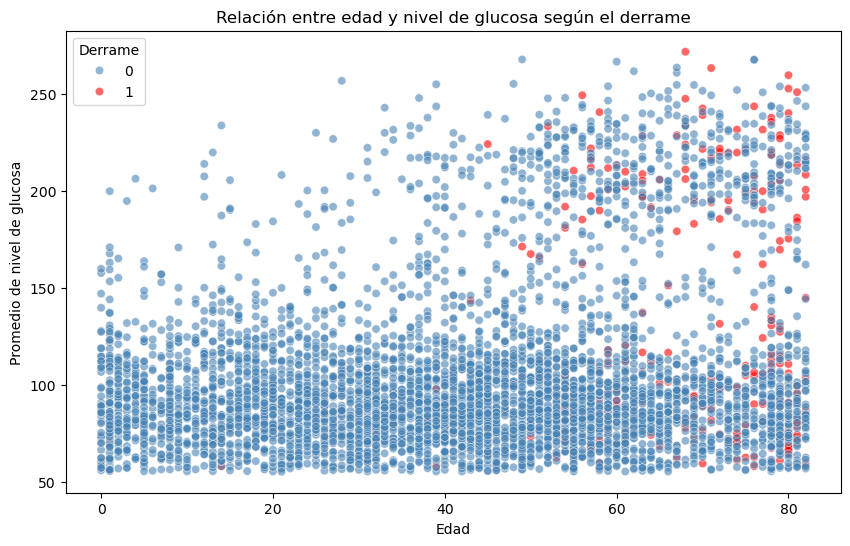

In [53]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=datosIcutus,
    x='Edad',
    y='PromNivelGlucosa',
    hue='Derrame',
    palette={0:'steelblue', 1:'red'},
    alpha=0.6
)

plt.title('Relación entre edad y nivel de glucosa según el derrame')
plt.xlabel('Edad')
plt.ylabel('Promedio de nivel de glucosa')
plt.legend(title='Derrame')
plt.show()

Al representar conjuntamente la edad, la glucosa y el derrame, se observa que las dos clases no forman grupos completamente separados. Aunque los casos positivos aparecen especialmente en pacientes de edades mayores, también hay pacientes de características similares sin derrame. Esto muestra la dificultad de realizar una predicción utilizando únicamente dos variables.

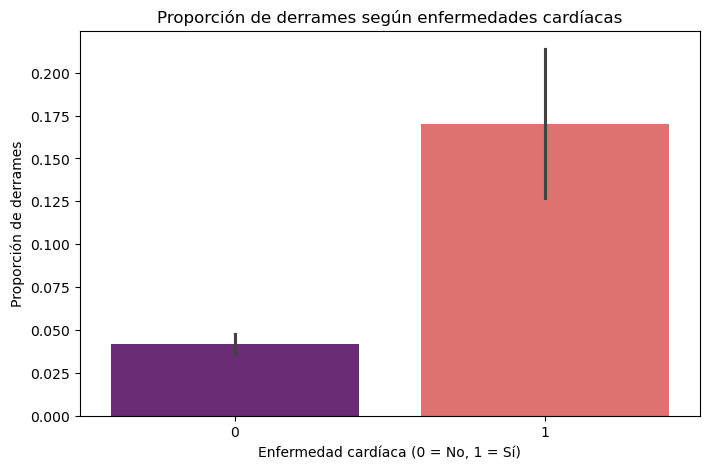

In [54]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=datosIcutus,
    x='EnfCardiaco',
    y='Derrame',
    hue='EnfCardiaco',
    palette='magma',
    legend=False
)

plt.title('Proporción de derrames según enfermedades cardíacas')
plt.xlabel('Enfermedad cardíaca (0 = No, 1 = Sí)')
plt.ylabel('Proporción de derrames')
plt.show()

La gráfica compara la proporción de derrames entre pacientes con y sin antecedentes de enfermedad cardíaca. Es más apropiado comparar estas proporciones que los conteos totales, porque los dos grupos tienen tamaños diferentes. La asociación observada debe interpretarse como descriptiva y no como una relación causal.

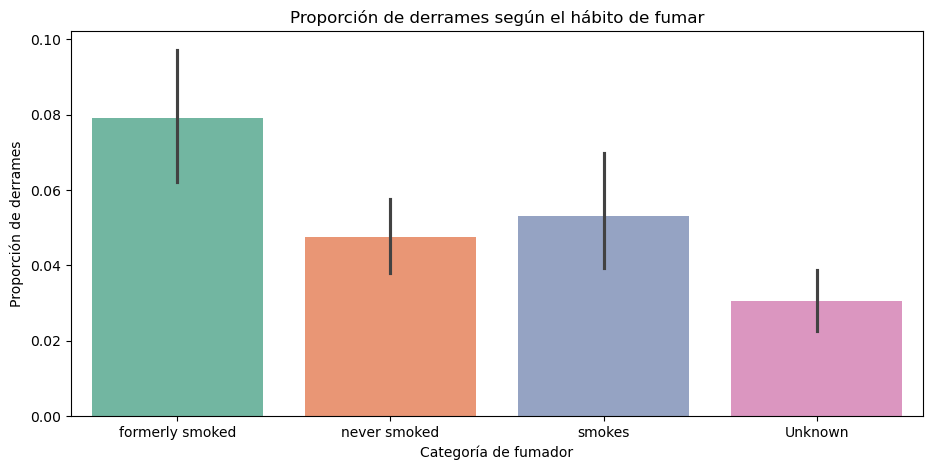

In [55]:
plt.figure(figsize=(11,5))

sns.barplot(
    data=datosIcutus,
    x='Fumador',
    y='Derrame',
    hue='Fumador',
    palette='Set2',
    legend=False
)

plt.title('Proporción de derrames según el hábito de fumar')
plt.xlabel('Categoría de fumador')
plt.ylabel('Proporción de derrames')
plt.show()

Las proporciones permiten comparar la frecuencia relativa de derrames en cada categoría de consumo de tabaco. Es importante considerar que 1.544 registros tienen el estado Unknown, lo cual limita una interpretación definitiva de las diferencias entre las categorías.

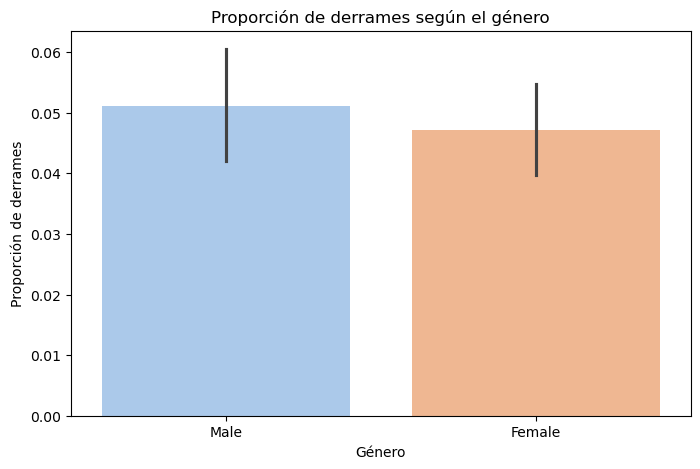

In [56]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=datosIcutus,
    x='Genero',
    y='Derrame',
    hue='Genero',
    palette='pastel',
    legend=False
)

plt.title('Proporción de derrames según el género')
plt.xlabel('Género')
plt.ylabel('Proporción de derrames')
plt.show()

La comparación por proporciones permite estudiar las diferencias entre hombres y mujeres sin que la mayor cantidad de mujeres en el dataset determine automáticamente el resultado. Las diferencias observadas describen la muestra, pero no permiten concluir que el género por sí solo explique la presencia de derrame cerebral.

In [117]:
# Se calculan los porcentajes de derrame para las variables categóricas
for variable in ['EnfCardiaco', 'Fumador', 'Genero']:
    print("\nVariable:", variable)
    print((datosIcutus.groupby(variable)['Derrame'].agg(['count','sum','mean'])
           .assign(Porcentaje=lambda x: (x['mean']*100).round(2))
           [['count','sum','Porcentaje']]))



Variable: EnfCardiaco
             count  sum  Porcentaje
EnfCardiaco                        
0             4833  202        4.18
1              276   47       17.03

Variable: Fumador
                 count  sum  Porcentaje
Fumador                                
Unknown           1544   47        3.04
formerly smoked    884   70        7.92
never smoked      1892   90        4.76
smokes             789   42        5.32

Variable: Genero
        count  sum  Porcentaje
Genero                        
Female   2994  141        4.71
Male     2115  108        5.11


### OBSERVACIONES DE EDAD CON ICTUS
- Se observa alto riesgo de ICTUS en personas mayores a 40 años
- Se requiere una columna con los pacientes mayores de 40 y con Promedio de Glucosa menor que 126
- Se requiere agregar una nueva columna que tenga pacientes de Alto Riesgo


In [57]:
##Se requiere agregar una nueva columna con riesgo
df04 = df03.withColumn('AltoRiesgo' , F.when ((F.col('Edad')>=40) & (F.col('PromNivelGlucosa') <= 125) ,1).otherwise(0))

df04.show(5)

+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|Casado|  TipoTrabajo|TipoResidencia|PromNivelGlucosa|  BMI|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|   Yes|      Private|         Urban|          228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|   Yes|Self-employed|         Rural|          202.21|30.72|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|   Yes|      Private|         Rural|          105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|   Yes|      Private|         Urban|          171.23| 34.4|         smokes|      1|         0|
| 1665|Female|  79|        

In [58]:
df04 = df03.withColumn("AltoRiesgo", F.when((F.col("Edad")>=40)&(F.col("PromNivelGlucosa")<126),1).otherwise(0))

df04.show(4)

+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|Casado|  TipoTrabajo|TipoResidencia|PromNivelGlucosa|  BMI|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|   Yes|      Private|         Urban|          228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|   Yes|Self-employed|         Rural|          202.21|30.72|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|   Yes|      Private|         Rural|          105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|   Yes|      Private|         Urban|          171.23| 34.4|         smokes|      1|         0|
+-----+------+----+--------

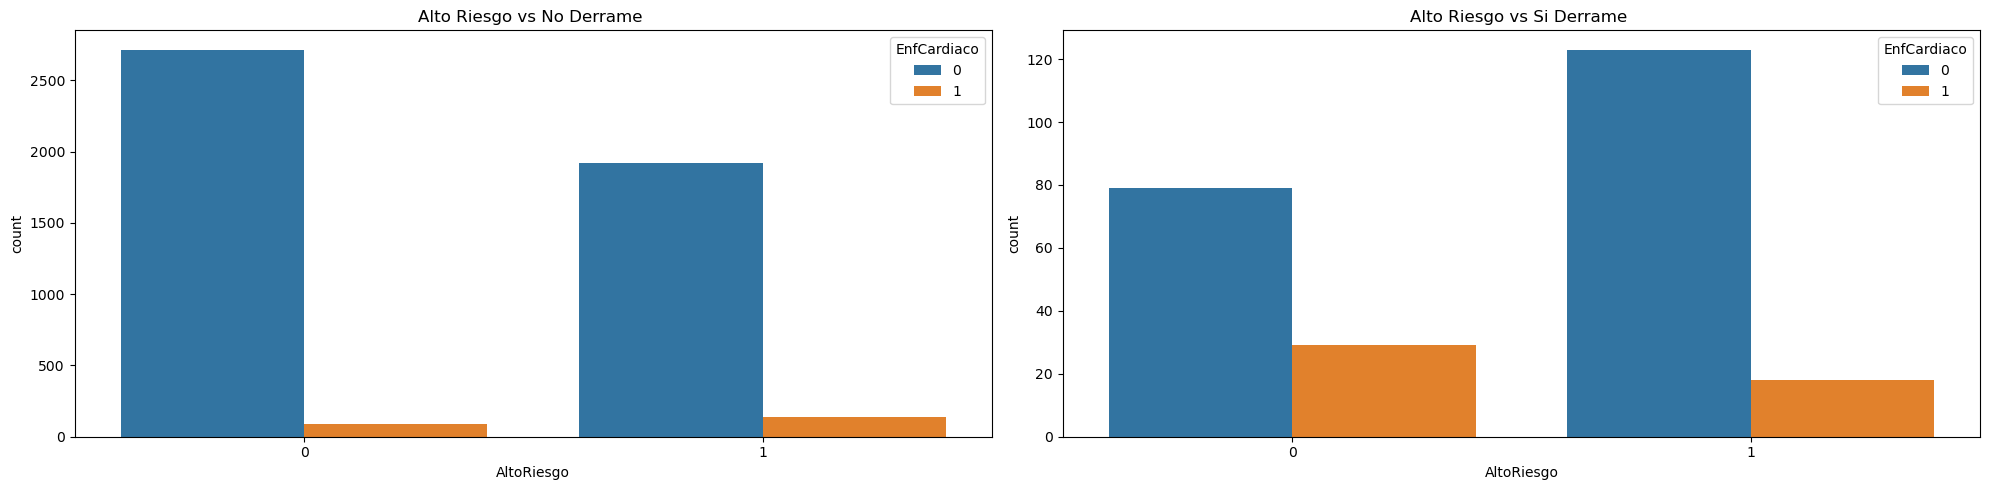

In [119]:
# Graficas en funcion de alto riesgo
# 1.- Alto riesgo contra derrame cerebral: EnfCardiaca

datosPandas = df04.toPandas()
#Se requiere una matriz 1x2 (1 fila por 2 columnas)
fig, matrix = plt.subplots(1, 2, figsize=(20, 5))
matrix[0].set_title("Alto Riesgo vs No Derrame ")
matrix0 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 0],
x='AltoRiesgo',
hue='EnfCardiaco',
ax=matrix[0]
)
matrix[1].set_title("Alto Riesgo vs Si Derrame ")
matrix1 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 1],
x='AltoRiesgo',
hue='EnfCardiaco',
ax=matrix[1]
)
plt.tight_layout()
plt.show()

Los paneles permiten comparar la distribución de pacientes según la variable AltoRiesgo y la presencia de enfermedad cardíaca, separando los casos con y sin derrame. Esta representación permite reconocer combinaciones de características presentes en los dos grupos. Sin embargo, como el número de pacientes sin derrame es mucho mayor, las diferencias de altura entre paneles deben interpretarse considerando el tamaño de cada grupo.

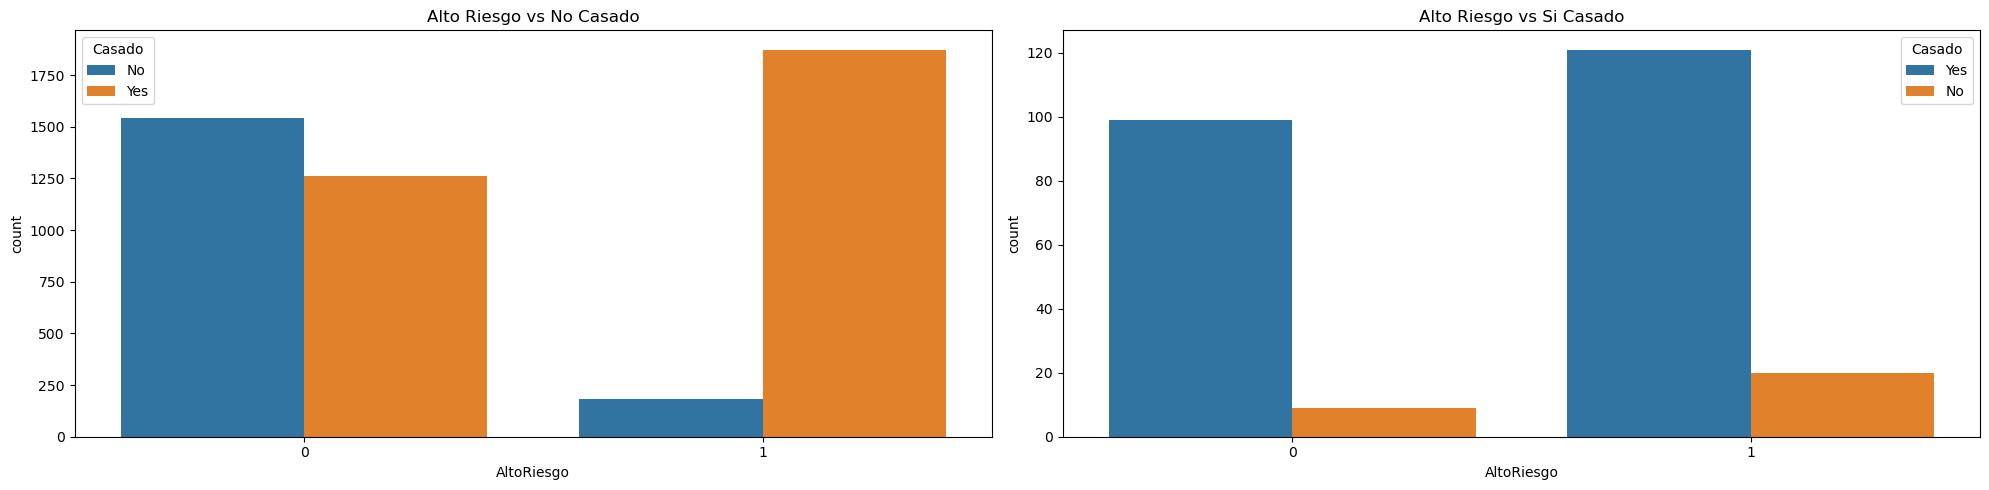

In [120]:
#Se requiere una matriz 1x2 (1 fila por 2 columnas)
fig, matrix = plt.subplots(1, 2, figsize=(20, 5))
matrix[0].set_title("Alto Riesgo vs No Casado")
matrix0 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 0],
x='AltoRiesgo',
hue='Casado',
ax=matrix[0]
)
matrix[1].set_title("Alto Riesgo vs Si Casado")
matrix1 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 1],
x='AltoRiesgo',
hue='Casado',
ax=matrix[1]
)
plt.tight_layout()
plt.show()

La gráfica permite revisar cómo se distribuyen las categorías de estado civil dentro de los grupos definidos por AltoRiesgo y Derrame. Las diferencias en las cantidades pueden estar influenciadas por la mayor presencia de pacientes registrados como Yes en el conjunto de datos. Por lo tanto, los conteos no son suficientes para afirmar una relación entre estado civil y presencia de derrame.

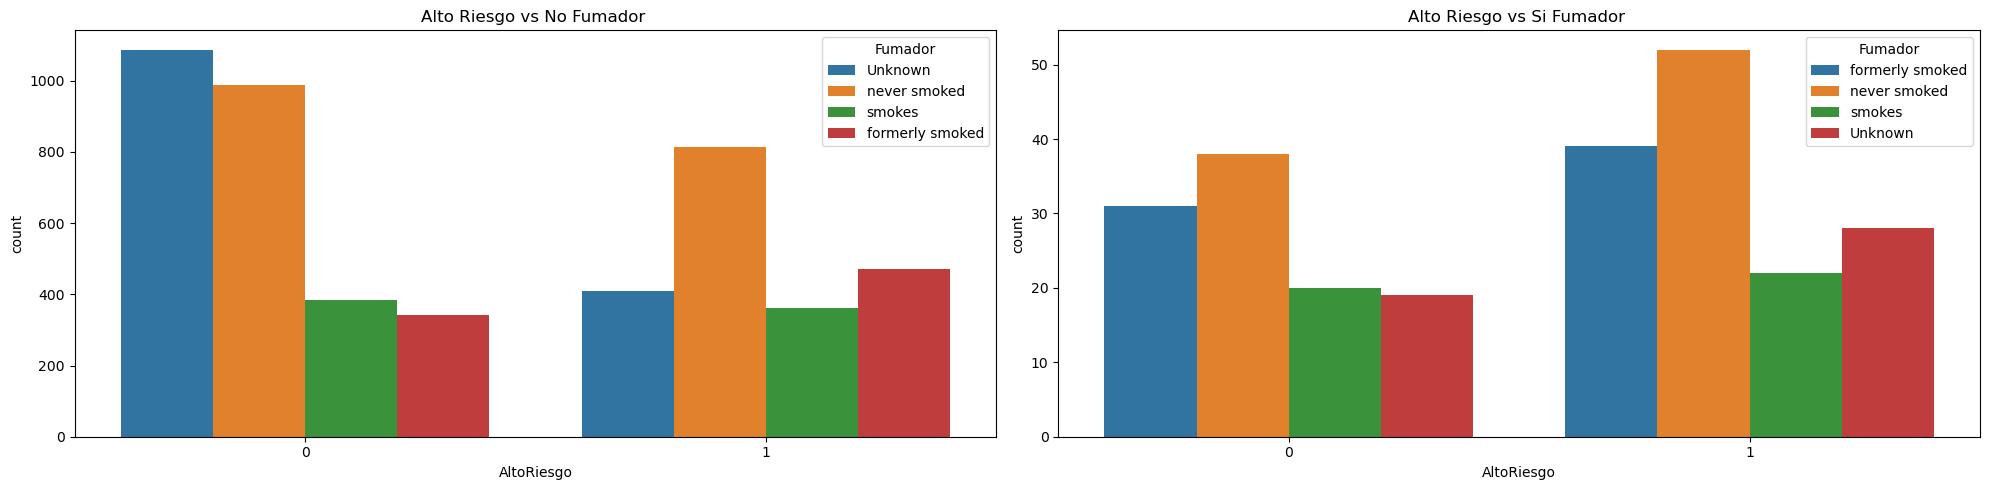

In [121]:
#Se requiere una matriz 1x2 (1 fila por 2 columnas)
fig, matrix = plt.subplots(1, 2, figsize=(20, 5))
matrix[0].set_title("Alto Riesgo vs No Fumador ")
matrix0 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 0],
x='AltoRiesgo',
hue='Fumador',
ax=matrix[0]
)
matrix[1].set_title("Alto Riesgo vs Si Fumador ")
matrix1 = sns.countplot(
data=datosPandas.loc[datosPandas['Derrame'] == 1],
x='AltoRiesgo',
hue='Fumador',
ax=matrix[1]
)
plt.tight_layout()
plt.show()

La comparación permite observar las distintas categorías del hábito de fumar entre pacientes con y sin derrame, considerando además la clasificación AltoRiesgo. La interpretación debe tener en cuenta tanto el desbalance de la variable Derrame como la cantidad de registros cuyo hábito de fumar es desconocido. Estos factores pueden dificultar la identificación de patrones claros.

In [62]:
#se revisa las variables
df04.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)
 |-- AltoRiesgo: integer (nullable = false)



In [63]:
df04.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

In [64]:
# se preparan las variables categoricas 
categoricas = ['id',
 'Genero',
 'Casado',
 'TipoTrabajo',
 'TipoResidencia',
 'Fumador']

In [65]:
# se preparan las no variables categoricas 
noCategoricas = ['Edad',
 'Hipertension',
 'EnfCardiaco',
 'PromNivelGlucosa',
 'BMI',
 'Derrame',
 'AltoRiesgo']

In [66]:
#Se realizan los indices en funcion de su posision [0,1,2...]
indices = [StringIndexer(inputCol=variable, outputCol=variable+"_IND").fit(df04)
          for variable in list(set(df04.columns) - set(noCategoricas))]

#Se realiza el pepeline para la etapa de cambio de categoria a numericos
tuberia = Pipeline(stages=indices)

#se crea una nueva version para no dañar nada 
df05 = tuberia.fit(df04).transform(df04)

df05 = df05.drop(*categoricas)

#Se inspecciona el objeto datafrmae pyspark
df05.show(4)

+----+------------+-----------+----------------+-----+-------+----------+----------+-----------+------+------------------+---------------+----------+
|Edad|Hipertension|EnfCardiaco|PromNivelGlucosa|  BMI|Derrame|AltoRiesgo|Casado_IND|Fumador_IND|id_IND|TipoResidencia_IND|TipoTrabajo_IND|Genero_IND|
+----+------------+-----------+----------------+-----+-------+----------+----------+-----------+------+------------------+---------------+----------+
|  67|           0|          1|          228.69| 36.6|      1|         0|       0.0|        2.0|5052.0|               0.0|            0.0|       1.0|
|  61|           0|          0|          202.21|30.72|      1|         0|       0.0|        0.0|3218.0|               1.0|            1.0|       0.0|
|  80|           0|          1|          105.92| 32.5|      1|         1|       0.0|        0.0|1593.0|               1.0|            0.0|       1.0|
|  49|           0|          0|          171.23| 34.4|      1|         0|       0.0|        3.0|3906

In [67]:
# Se retira id_IND
df05 = df05.drop("id_IND")

# Se inspecciona el objeto dataframe pyspark
df05.show(4)

+----+------------+-----------+----------------+-----+-------+----------+----------+-----------+------------------+---------------+----------+
|Edad|Hipertension|EnfCardiaco|PromNivelGlucosa|  BMI|Derrame|AltoRiesgo|Casado_IND|Fumador_IND|TipoResidencia_IND|TipoTrabajo_IND|Genero_IND|
+----+------------+-----------+----------------+-----+-------+----------+----------+-----------+------------------+---------------+----------+
|  67|           0|          1|          228.69| 36.6|      1|         0|       0.0|        2.0|               0.0|            0.0|       1.0|
|  61|           0|          0|          202.21|30.72|      1|         0|       0.0|        0.0|               1.0|            1.0|       0.0|
|  80|           0|          1|          105.92| 32.5|      1|         1|       0.0|        0.0|               1.0|            0.0|       1.0|
|  49|           0|          0|          171.23| 34.4|      1|         0|       0.0|        3.0|               0.0|            0.0|       0.0|

La preparacion de los datos no ha sido del todo satisfactoria, se debe realizar mejor estudio sobre todo de los outliers o comportamientos atipicos, entre otros. 


### **Implementación de modelos de machine learning usando MLlib**

- Creación de vector de caracteristicas (variables independientes)
- División para entrenamiento y prueba con el 20 % de los datos
- Se ejecutan los modelos seleccionados
- Se evaluan los modelos con las métricas de rendimiento

#### **Creación de vector de caracteristicas (variables independientes)**

In [68]:
#Se realiza el vector de categorias:
varIndependientes = VectorAssembler(inputCols=df05.drop('Derrame').columns, outputCol='independientes')

vectorIndependientes = varIndependientes.transform(df05).select('independientes','Derrame')

# Se observa el vector
vectorIndependientes.show(5)

+--------------------+-------+
|      independientes|Derrame|
+--------------------+-------+
|(11,[0,2,3,4,7,10...|      1|
|(11,[0,3,4,8,9],[...|      1|
|[80.0,0.0,1.0,105...|      1|
|(11,[0,3,4,7],[49...|      1|
|(11,[0,1,3,4,8,9]...|      1|
+--------------------+-------+
only showing top 5 rows



In [69]:
vectorIndependientes.show(10, False)

+--------------------------------------------------+-------+
|independientes                                    |Derrame|
+--------------------------------------------------+-------+
|(11,[0,2,3,4,7,10],[67.0,1.0,228.69,36.6,2.0,1.0])|1      |
|(11,[0,3,4,8,9],[61.0,202.21,30.72,1.0,1.0])      |1      |
|[80.0,0.0,1.0,105.92,32.5,1.0,0.0,0.0,1.0,0.0,1.0]|1      |
|(11,[0,3,4,7],[49.0,171.23,34.4,3.0])             |1      |
|(11,[0,1,3,4,8,9],[79.0,1.0,174.12,24.0,1.0,1.0]) |1      |
|(11,[0,3,4,7,10],[81.0,186.21,29.0,2.0,1.0])      |1      |
|[74.0,1.0,1.0,70.09,27.4,1.0,0.0,0.0,1.0,0.0,1.0] |1      |
|(11,[0,3,4,5,6],[69.0,94.39,22.8,1.0,1.0])        |1      |
|(11,[0,3,4,5,7,8],[59.0,76.15,31.92,1.0,1.0,1.0]) |1      |
|(11,[0,3,4,5,7],[78.0,58.57,24.2,1.0,1.0])        |1      |
+--------------------------------------------------+-------+
only showing top 10 rows



#### **División para entrenamiento y prueba con el 20 % de los datos**

In [70]:
# Se crea un datafram spark desde el vector 
df06 = vectorIndependientes.select(['independientes', 'Derrame'])

#train -> conjunto de entrenamiento 80 % de los datos
#test -> conjunto de pruebas 20 % de los datos
train, test = df06.randomSplit([0.8, 0.2])

In [71]:
# Se requiere revisar el porcentaje de Derrrame=1 en el conjunto de entrenamiento (train)
totalTrain = float(train.select('Derrame').count())
conDerrameTrain = train.select('Derrame').where('Derrame == 1').count()

porcentajeConDerrameTrain = (float(conDerrameTrain)/float(totalTrain))*100
noDerrameTrain = float(totalTrain-conDerrameTrain)
print(f"Cantidad de con Derrame en conjunto de entrenamiento = {conDerrameTrain}")
print(f"Porcentaje de con Derrame en conjunto de entrenamiento = {round(porcentajeConDerrameTrain,2)}%")

Cantidad de con Derrame en conjunto de entrenamiento = 200
Porcentaje de con Derrame en conjunto de entrenamiento = 4.84%


Se realiza este análisis para conocer la distribución de la variable objetivo Derrame en el conjunto de entrenamiento y determinar si existe un desbalance entre los casos con derrame y sin derrame. Esto es fundamental porque un desbalance importante puede afectar el aprendizaje y el rendimiento del modelo predictivo.

Los resultados indican que existe un posible desbalance de clases, ya que los casos de derrame representan una proporción pequeña del conjunto de entrenamiento. Esto debe tenerse en cuenta al entrenar y evaluar el modelo de Machine Learning.

#### **Se ejecutan los modelos seleccionados**

### **Regresión Logística**
Es conveniente porque permite desarrollar un modelo predictivo capaz de estimar la probabilidad de que una persona presente un derrame cerebral a partir de sus características y variables independientes.

In [72]:
from  pyspark.ml.classification import LogisticRegression
# Se instancia el modelo de Regresión Logística
RegreLog = LogisticRegression(featuresCol='independientes', labelCol='Derrame')
#Se aplica el modelo de Regresión Logística sobre los datos de entrenamiento: "se entrena el modelo"
modeloRegLog = RegreLog.fit(train)

#### **Se evaluan los modelo de Regresión Logística**

In [73]:
## Se hacen las predicciones sobre los dato de prueba en el modelo de Regresión Logística
predRLog = modeloRegLog.transform(test)

# Se seleccionan las columnas
resultadosRLog = predRLog.select('probability', 'Derrame')

# Se recopilan los resultados
coleccResultadosRLog = resultadosRLog.collect()

# Se genera una lista
resultListaRLog = [
    (float(i[0][1]), float(i[1]))
    for i in coleccResultadosRLog
]

# Se obtiene el contexto de Spark
sparkContextGarcia = sparkGarcia.sparkContext

# Se realizan las puntuaciones
puntuacionRLog = sparkContextGarcia.parallelize(resultListaRLog)

In [75]:
# Impresion de metricas sobre resultados de prueba
from pyspark.mllib.evaluation import BinaryClassificationMetrics as Metricas

metricasRLog = Metricas(puntuacionRLog)
#Curva AUC
ACURlog = metricasRLog.areaUnderROC
accurayRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName = 'accuracy').evaluate(predRLog)
precisRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName = 'weightedPrecision').evaluate(predRLog)
recallRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName = 'weightedRecall').evaluate(predRLog)

/mnt/sda1/Cluster/Spark/python/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
                                                                                

In [77]:
# se imprimen
print(f"AUC-ROC : {round(ACURlog,2)}%")
print(f"Accuracy : {round(accurayRlog,2)}%")
print(f"Precision ponderada : {round(precisRlog, 4)}%")
print(f"Recall ponderado : {round(recallRlog, 4)}%")

AUC-ROC : 0.82%
Accuracy : 0.95%
Precision ponderada : 0.9021%
Recall ponderado : 0.9498%


### Análisis y gráficas de la Regresión Logística
Se revisan las predicciones, la matriz de confusión y las métricas de la clase Derrame = 1. Como hay pocos casos positivos, interesa especialmente cuántos logra identificar el modelo.

In [78]:
# Se cuentan las predicciones de la regresión logística
matrizRLog = predRLog.groupBy('Derrame','prediction').count().toPandas()
print(matrizRLog.sort_values(['Derrame','prediction']).to_string(index=False))

 Derrame  prediction  count
       0         0.0    927
       1         0.0     49


prediction  0.0  1.0
Derrame             
0.0         927    0
1.0          49    0


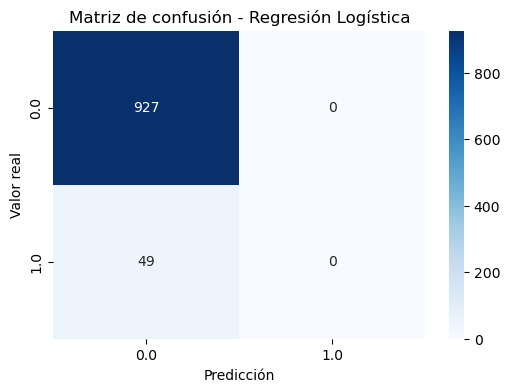

In [79]:
# Se construye la matriz de confusión de la Regresión Logística
tablaRLog = pd.crosstab(matrizRLog['Derrame'], matrizRLog['prediction'],values=matrizRLog['count'],aggfunc='sum').reindex(index=[0.0,1.0],columns=[0.0,1.0],fill_value=0).fillna(0).astype(int)
print(tablaRLog)
plt.figure(figsize=(6,4))
sns.heatmap(tablaRLog,annot=True,fmt='d',cmap='Blues')
plt.title('Matriz de confusión - Regresión Logística')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [80]:
# Se calculan los verdaderos y falsos positivos y negativos
TN_RLog = int(tablaRLog.loc[0.0,0.0])
FP_RLog = int(tablaRLog.loc[0.0,1.0])
FN_RLog = int(tablaRLog.loc[1.0,0.0])
TP_RLog = int(tablaRLog.loc[1.0,1.0])
precision1RLog = TP_RLog/(TP_RLog+FP_RLog) if TP_RLog+FP_RLog>0 else 0
recall1RLog = TP_RLog/(TP_RLog+FN_RLog) if TP_RLog+FN_RLog>0 else 0
f1RLog = 2*precision1RLog*recall1RLog/(precision1RLog+recall1RLog) if precision1RLog+recall1RLog>0 else 0
print(f"TP={TP_RLog}, TN={TN_RLog}, FP={FP_RLog}, FN={FN_RLog}")
print(f"Precisión clase 1: {precision1RLog:.4f}")
print(f"Recall clase 1: {recall1RLog:.4f}")
print(f"F1 clase 1: {f1RLog:.4f}")

TP=0, TN=927, FP=0, FN=49
Precisión clase 1: 0.0000
Recall clase 1: 0.0000
F1 clase 1: 0.0000


In [81]:
# Se interpreta la matriz de confusión con los resultados obtenidos
print(f"Análisis: El modelo identificó correctamente {TP_RLog} de {TP_RLog+FN_RLog} pacientes con derrame ({recall1RLog*100:.2f}%).")
print(f"Dejó sin identificar {FN_RLog} casos reales de derrame y señaló como positivos {FP_RLog} pacientes sin derrame.")
print(f"Aunque el accuracy fue {accurayRlog*100:.2f}%, el recall de la clase 1 fue {recall1RLog*100:.2f}%. La diferencia es importante porque hay muchos más pacientes sin derrame.")

Análisis: El modelo identificó correctamente 0 de 49 pacientes con derrame (0.00%).
Dejó sin identificar 49 casos reales de derrame y señaló como positivos 0 pacientes sin derrame.
Aunque el accuracy fue 94.98%, el recall de la clase 1 fue 0.00%. La diferencia es importante porque hay muchos más pacientes sin derrame.


Distribución de probabilidades de la Regresión Logística
Se analizan las probabilidades calculadas por el modelo para determinar si asigna valores diferentes a los pacientes con y sin derrame cerebral.

In [122]:
# Se obtienen las probabilidades de derrame de la regresión logística
probRLog = predRLog.select('Derrame', 'probability').toPandas()

# Se extrae la probabilidad de la clase 1
probRLog['ProbDerrame'] = probRLog['probability'].apply(lambda x: float(x[1]))

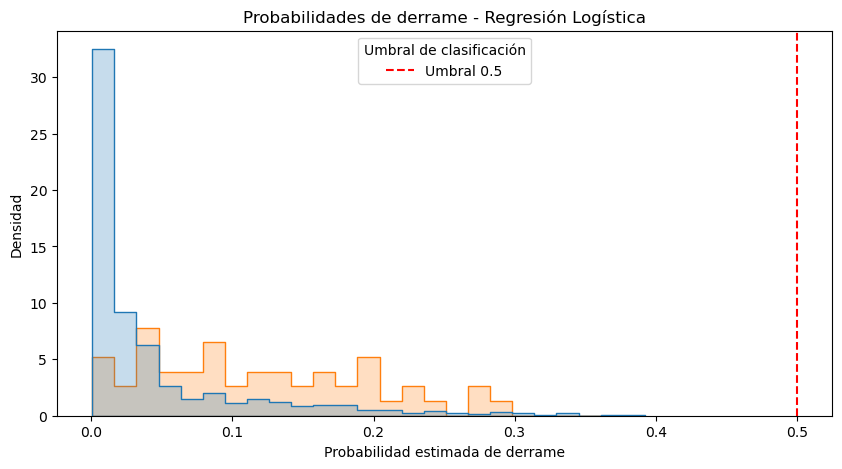

In [123]:
# Se grafica la distribución de probabilidades
plt.figure(figsize=(10,5))
sns.histplot(data=probRLog, x='ProbDerrame',
             hue='Derrame', bins=25, stat='density',
             common_norm=False, element='step')

plt.axvline(0.5, color='red', linestyle='--', label='Umbral 0.5')
plt.title('Probabilidades de derrame - Regresión Logística')
plt.xlabel('Probabilidad estimada de derrame')
plt.ylabel('Densidad')
plt.legend(title='Umbral de clasificación')
plt.show()

In [124]:
# Se revisan las probabilidades promedio por clase
print(probRLog.groupby('Derrame')['ProbDerrame']
      .agg(['mean','max','min']).round(4))


           mean     max     min
Derrame                        
0        0.0437  0.3923  0.0006
1        0.1174  0.2828  0.0097


El modelo de regresión logística obtuvo un AUC-ROC de 0,8214 y una exactitud del 94,98 %. Sin embargo, al revisar la matriz de confusión se encontró que los 49 pacientes con derrame fueron clasificados incorrectamente como negativos.

La distribución de probabilidades permite observar cómo el modelo asigna puntuaciones a ambos grupos. Aunque el AUC-ROC indica que existe capacidad para ordenar los pacientes según su probabilidad de derrame, ninguna predicción superó el umbral de clasificación utilizado para identificar correctamente un caso positivo.

Por lo tanto, el modelo distingue parcialmente los niveles de riesgo, pero con su configuración actual no consigue identificar los casos de derrame en el conjunto de prueba.

### **Modelo Árbol de Decisión**
Se utiliza porque permite clasificar a los pacientes mediante reglas de decisión basadas en sus características. Además, facilita identificar qué variables tienen mayor importancia en la predicción de un derrame cerebral.

In [82]:
# Se importa el modelo Árbol de Decisión
from pyspark.ml.classification import DecisionTreeClassifier

In [83]:
# Se importa el modelo Árbol de Decisión
from pyspark.ml.classification import DecisionTreeClassifier

In [84]:
# Se instancia el modelo Árbol de Decisión
clasificadorArbol = DecisionTreeClassifier(featuresCol='independientes', labelCol='Derrame', maxDepth=5)

In [85]:
# Se entrena el modelo con los datos de entrenamiento
modeloArbol = clasificadorArbol.fit(train)

In [86]:
# Se hacen las predicciones sobre el conjunto de prueba
predArbol = modeloArbol.transform(test)
predArbol.select('Derrame','prediction','probability').show(5,False)

+-------+----------+-----------------------------------------+
|Derrame|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.6818181818181818,0.3181818181818182]  |
|0      |0.0       |[0.9882937211777226,0.011706278822277403]|
|0      |0.0       |[0.9882937211777226,0.011706278822277403]|
|0      |0.0       |[0.82,0.18]                              |
|0      |0.0       |[0.9882937211777226,0.011706278822277403]|
+-------+----------+-----------------------------------------+
only showing top 5 rows



In [87]:
# Se calculan las métricas del modelo Árbol de Decisión
from pyspark.ml.evaluation import BinaryClassificationEvaluator
aucArbol = BinaryClassificationEvaluator(labelCol='Derrame',rawPredictionCol='rawPrediction',metricName='areaUnderROC').evaluate(predArbol)
accuracyArbol = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='accuracy').evaluate(predArbol)
precisionPondArbol = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedPrecision').evaluate(predArbol)
recallPondArbol = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedRecall').evaluate(predArbol)

In [88]:
# Se cuentan los casos reales y las predicciones
matrizArbol = predArbol.groupBy('Derrame','prediction').count().toPandas()
print(matrizArbol.sort_values(['Derrame','prediction']).to_string(index=False))

 Derrame  prediction  count
       0         0.0    922
       0         1.0      5
       1         0.0     49


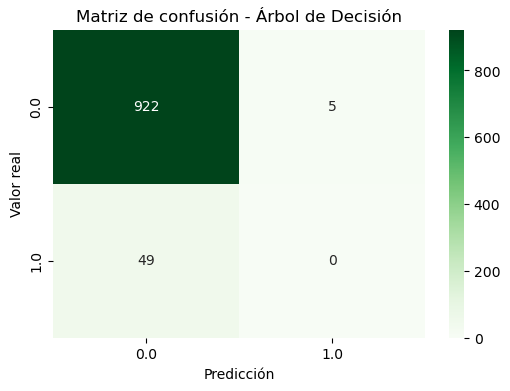

In [89]:
# Se dibuja la matriz de confusión
tablaArbol = pd.crosstab(matrizArbol['Derrame'],matrizArbol['prediction'],values=matrizArbol['count'],aggfunc='sum').reindex(index=[0.0,1.0],columns=[0.0,1.0],fill_value=0).fillna(0).astype(int)
plt.figure(figsize=(6,4))
sns.heatmap(tablaArbol,annot=True,fmt='d',cmap='Greens')
plt.title('Matriz de confusión - Árbol de Decisión')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [90]:
# Se calculan las métricas específicas de los casos con derrame
TN_Arbol = int(tablaArbol.loc[0.0,0.0])
FP_Arbol = int(tablaArbol.loc[0.0,1.0])
FN_Arbol = int(tablaArbol.loc[1.0,0.0])
TP_Arbol = int(tablaArbol.loc[1.0,1.0])
precision1Arbol = TP_Arbol/(TP_Arbol+FP_Arbol) if TP_Arbol+FP_Arbol>0 else 0
recall1Arbol = TP_Arbol/(TP_Arbol+FN_Arbol) if TP_Arbol+FN_Arbol>0 else 0
f1Arbol = 2*precision1Arbol*recall1Arbol/(precision1Arbol+recall1Arbol) if precision1Arbol+recall1Arbol>0 else 0
print(f"TP={TP_Arbol}, TN={TN_Arbol}, FP={FP_Arbol}, FN={FN_Arbol}")
print(f"Precisión clase 1: {precision1Arbol:.4f}")
print(f"Recall clase 1: {recall1Arbol:.4f}")
print(f"F1 clase 1: {f1Arbol:.4f}")

TP=0, TN=922, FP=5, FN=49
Precisión clase 1: 0.0000
Recall clase 1: 0.0000
F1 clase 1: 0.0000


In [91]:
# Se analizan los resultados numéricos del modelo Árbol de Decisión
print(f"Análisis: El modelo identificó {TP_Arbol} de {TP_Arbol+FN_Arbol} pacientes con derrame ({recall1Arbol*100:.2f}%).")
print(f"Se presentaron {FN_Arbol} falsos negativos y {FP_Arbol} falsos positivos.")
print(f"El accuracy fue {accuracyArbol*100:.2f}%, mientras que el recall de la clase 1 fue {recall1Arbol*100:.2f}%.")
print('La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.')

Análisis: El modelo identificó 0 de 49 pacientes con derrame (0.00%).
Se presentaron 49 falsos negativos y 5 falsos positivos.
El accuracy fue 94.47%, mientras que el recall de la clase 1 fue 0.00%.
La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.


Importancia de las variables en el Árbol de Decisión
Se identifican las características con mayor importancia dentro del árbol entrenado, con el fin de conocer cuáles utiliza principalmente para realizar sus clasificaciones.

In [125]:

# Se obtienen los nombres y la importancia de las variables
nombresArbol = varIndependientes.getInputCols()
importanciasArbol = modeloArbol.featureImportances.toArray()

datosArbol = pd.DataFrame({
    'Variable': nombresArbol,
    'Importancia': importanciasArbol
})

datosArbol = datosArbol.sort_values('Importancia', ascending=False)

print(datosArbol)


              Variable  Importancia
0                 Edad     0.625851
4                  BMI     0.126394
3     PromNivelGlucosa     0.091077
2          EnfCardiaco     0.046918
7          Fumador_IND     0.037746
9      TipoTrabajo_IND     0.036878
6           Casado_IND     0.035136
1         Hipertension     0.000000
5           AltoRiesgo     0.000000
8   TipoResidencia_IND     0.000000
10          Genero_IND     0.000000


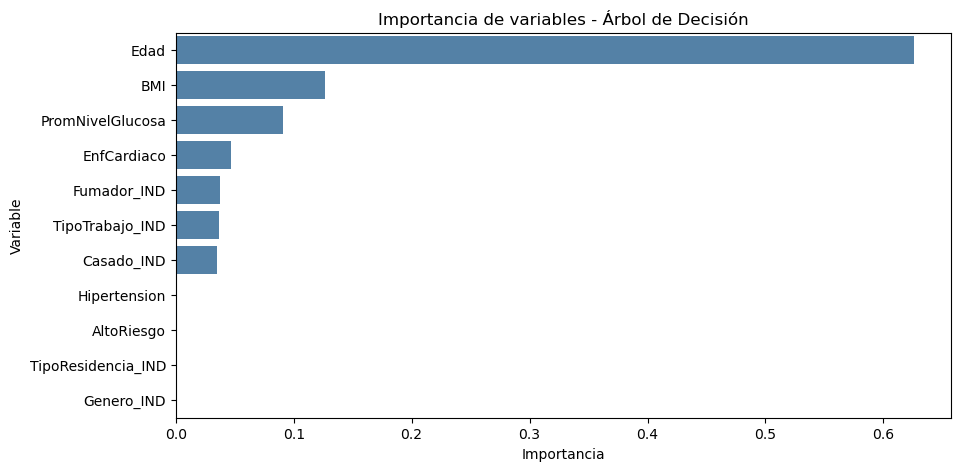

In [126]:
# Se grafican las variables más importantes
plt.figure(figsize=(10,5))
sns.barplot(data=datosArbol, x='Importancia', y='Variable',
            color='steelblue')

plt.title('Importancia de variables - Árbol de Decisión')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.show()


La gráfica permite identificar cuáles características tuvieron mayor participación en las divisiones realizadas por el árbol de decisión. Las variables con importancia más elevada son aquellas que más contribuyeron a reducir la impureza durante el entrenamiento, mientras que las variables con valor cero no fueron utilizadas en las divisiones del árbol.

Sin embargo, la importancia de las variables no garantiza un buen desempeño predictivo. El modelo obtuvo un AUC-ROC de 0,4717 y una exactitud del 94,47 %, pero no identificó correctamente ninguno de los 49 pacientes con derrame. Además, clasificó incorrectamente como positivos a cinco pacientes que no habían presentado el evento.

Por lo tanto, las decisiones aprendidas por el árbol no permitieron diferenciar adecuadamente la clase positiva en los datos de prueba.

### **Modelo Random Forest**
Se utiliza porque combina varios árboles de decisión para realizar predicciones más estables y reducir los errores de un árbol individual. Esto permite evaluar si la combinación de múltiples árboles mejora la clasificación de pacientes con derrame cerebral.

In [92]:
# Se importa el modelo Random Forest
from pyspark.ml.classification import RandomForestClassifier

In [93]:
# Se instancia el modelo Random Forest
clasificadorBosque = RandomForestClassifier(featuresCol='independientes', labelCol='Derrame', numTrees=50, maxDepth=5)

In [94]:
# Se entrena el modelo con los datos de entrenamiento
modeloBosque = clasificadorBosque.fit(train)

In [95]:
# Se hacen las predicciones sobre el conjunto de prueba
predBosque = modeloBosque.transform(test)
predBosque.select('Derrame','prediction','probability').show(5,False)

+-------+----------+-----------------------------------------+
|Derrame|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.7916505524885187,0.2083494475114814]  |
|0      |0.0       |[0.9695993030866732,0.030400696913326763]|
|0      |0.0       |[0.935312888895143,0.06468711110485699]  |
|0      |0.0       |[0.8606962664073304,0.13930373359266954] |
|0      |0.0       |[0.9617113389256808,0.038288661074319184]|
+-------+----------+-----------------------------------------+
only showing top 5 rows



In [96]:
# Se calculan las métricas del modelo Random Forest
from pyspark.ml.evaluation import BinaryClassificationEvaluator
aucBosque = BinaryClassificationEvaluator(labelCol='Derrame',rawPredictionCol='rawPrediction',metricName='areaUnderROC').evaluate(predBosque)
accuracyBosque = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='accuracy').evaluate(predBosque)
precisionPondBosque = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedPrecision').evaluate(predBosque)
recallPondBosque = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedRecall').evaluate(predBosque)

In [97]:
# Se imprimen los resultados del modelo Random Forest
print(f"AUC-ROC: {aucBosque:.4f}")
print(f"Accuracy: {accuracyBosque:.4f}")
print(f"Precisión ponderada: {precisionPondBosque:.4f}")
print(f"Recall ponderado: {recallPondBosque:.4f}")

AUC-ROC: 0.8265
Accuracy: 0.9498
Precisión ponderada: 0.9021
Recall ponderado: 0.9498


In [98]:
# Se cuentan los casos reales y las predicciones
matrizBosque = predBosque.groupBy('Derrame','prediction').count().toPandas()
print(matrizBosque.sort_values(['Derrame','prediction']).to_string(index=False))

 Derrame  prediction  count
       0         0.0    927
       1         0.0     49


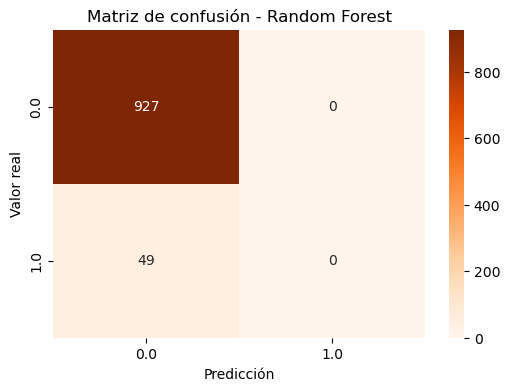

In [99]:
# Se dibuja la matriz de confusión
tablaBosque = pd.crosstab(matrizBosque['Derrame'],matrizBosque['prediction'],values=matrizBosque['count'],aggfunc='sum').reindex(index=[0.0,1.0],columns=[0.0,1.0],fill_value=0).fillna(0).astype(int)
plt.figure(figsize=(6,4))
sns.heatmap(tablaBosque,annot=True,fmt='d',cmap='Oranges')
plt.title('Matriz de confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [100]:
# Se calculan las métricas específicas de los casos con derrame
TN_Bosque = int(tablaBosque.loc[0.0,0.0])
FP_Bosque = int(tablaBosque.loc[0.0,1.0])
FN_Bosque = int(tablaBosque.loc[1.0,0.0])
TP_Bosque = int(tablaBosque.loc[1.0,1.0])
precision1Bosque = TP_Bosque/(TP_Bosque+FP_Bosque) if TP_Bosque+FP_Bosque>0 else 0
recall1Bosque = TP_Bosque/(TP_Bosque+FN_Bosque) if TP_Bosque+FN_Bosque>0 else 0
f1Bosque = 2*precision1Bosque*recall1Bosque/(precision1Bosque+recall1Bosque) if precision1Bosque+recall1Bosque>0 else 0
print(f"TP={TP_Bosque}, TN={TN_Bosque}, FP={FP_Bosque}, FN={FN_Bosque}")
print(f"Precisión clase 1: {precision1Bosque:.4f}")
print(f"Recall clase 1: {recall1Bosque:.4f}")
print(f"F1 clase 1: {f1Bosque:.4f}")

TP=0, TN=927, FP=0, FN=49
Precisión clase 1: 0.0000
Recall clase 1: 0.0000
F1 clase 1: 0.0000


In [101]:
# Se analizan los resultados numéricos del modelo Random Forest
print(f"Análisis: El modelo identificó {TP_Bosque} de {TP_Bosque+FN_Bosque} pacientes con derrame ({recall1Bosque*100:.2f}%).")
print(f"Se presentaron {FN_Bosque} falsos negativos y {FP_Bosque} falsos positivos.")
print(f"El accuracy fue {accuracyBosque*100:.2f}%, mientras que el recall de la clase 1 fue {recall1Bosque*100:.2f}%.")
print('La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.')

Análisis: El modelo identificó 0 de 49 pacientes con derrame (0.00%).
Se presentaron 49 falsos negativos y 0 falsos positivos.
El accuracy fue 94.98%, mientras que el recall de la clase 1 fue 0.00%.
La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.


Importancia de las variables en Random Forest
Se analiza la importancia de las características utilizadas por los 50 árboles que conforman el modelo Random Forest, para identificar cuáles contribuyen principalmente a sus predicciones.

In [127]:
# Se obtiene la importancia de las variables de Random Forest
importanciasBosque = modeloBosque.featureImportances.toArray()

datosBosque = pd.DataFrame({
    'Variable': varIndependientes.getInputCols(),
    'Importancia': importanciasBosque
})

datosBosque = datosBosque.sort_values('Importancia', ascending=False)
print(datosBosque)

              Variable  Importancia
0                 Edad     0.422262
3     PromNivelGlucosa     0.152692
4                  BMI     0.117898
2          EnfCardiaco     0.073523
1         Hipertension     0.053240
6           Casado_IND     0.045780
9      TipoTrabajo_IND     0.043857
7          Fumador_IND     0.036883
5           AltoRiesgo     0.034471
8   TipoResidencia_IND     0.011750
10          Genero_IND     0.007643


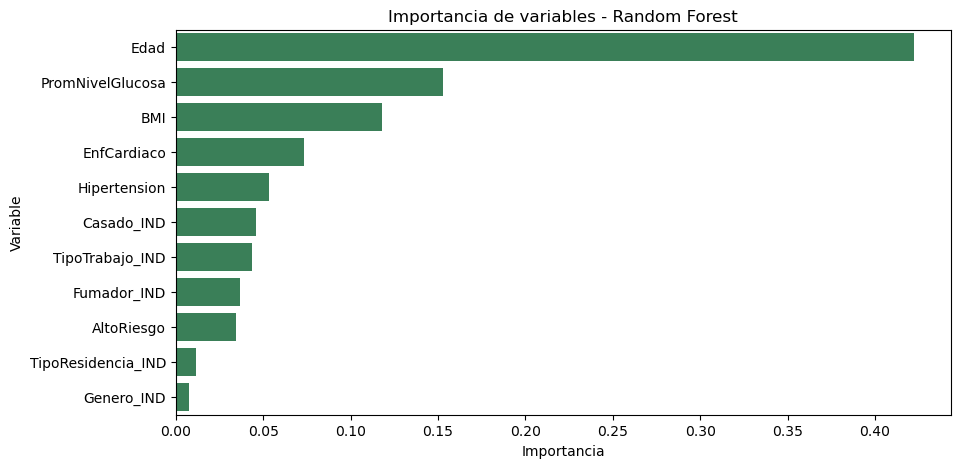

In [129]:
# Se grafica la importancia de las variables
plt.figure(figsize=(10,5))
sns.barplot(data=datosBosque, x='Importancia', y='Variable',
            color='seagreen')

plt.title('Importancia de variables - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.show()


La gráfica presenta la importancia de las variables utilizadas por Random Forest al combinar las decisiones de 50 árboles. Este análisis permite identificar qué características contribuyeron en mayor medida a las divisiones del conjunto de árboles y comparar su comportamiento con el árbol de decisión individual.

Random Forest obtuvo el AUC-ROC más alto de los cuatro modelos, con un valor de 0,8265, y una exactitud del 94,98 %. Sin embargo, su matriz de confusión muestra que los 927 pacientes sin derrame fueron clasificados correctamente, mientras que los 49 pacientes con derrame fueron identificados como negativos.

Esto indica que el modelo tiene capacidad para ordenar los casos según sus puntuaciones, pero no logra reconocer pacientes con derrame utilizando el umbral de clasificación actual.

### **Modelo Gradient Boosted Trees**
Se utiliza porque construye árboles de decisión de manera secuencial, intentando corregir los errores de los anteriores. Esto permite evaluar si un modelo más avanzado logra mejorar la identificación de pacientes con derrame cerebral.

In [102]:
# Se importa el modelo Gradient Boosted Trees
from pyspark.ml.classification import GBTClassifier

In [103]:
# Se instancia el modelo Gradient Boosted Trees
clasificadorGBT = GBTClassifier(featuresCol='independientes', labelCol='Derrame', maxIter=20, maxDepth=5)

In [104]:
# Se entrena el modelo con los datos de entrenamiento
modeloGBT = clasificadorGBT.fit(train)

In [105]:
# Se hacen las predicciones sobre el conjunto de prueba
predGBT = modeloGBT.transform(test)
predGBT.select('Derrame','prediction','probability').show(5,False)

+-------+----------+-----------------------------------------+
|Derrame|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.7195572491407609,0.2804427508592391]  |
|0      |0.0       |[0.9510767016754901,0.04892329832450992] |
|0      |0.0       |[0.8567867502599253,0.14321324974007466] |
|0      |0.0       |[0.8496718092087642,0.15032819079123583] |
|0      |0.0       |[0.9514618198515024,0.048538180148497645]|
+-------+----------+-----------------------------------------+
only showing top 5 rows



In [106]:
# Se calculan las métricas del modelo Gradient Boosted Trees
from pyspark.ml.evaluation import BinaryClassificationEvaluator
aucGBT = BinaryClassificationEvaluator(labelCol='Derrame',rawPredictionCol='rawPrediction',metricName='areaUnderROC').evaluate(predGBT)
accuracyGBT = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='accuracy').evaluate(predGBT)
precisionPondGBT = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedPrecision').evaluate(predGBT)
recallPondGBT = MulticlassClassificationEvaluator(labelCol='Derrame',metricName='weightedRecall').evaluate(predGBT)

In [107]:
# Se imprimen los resultados del modelo Gradient Boosted Trees
print(f"AUC-ROC: {aucGBT:.4f}")
print(f"Accuracy: {accuracyGBT:.4f}")
print(f"Precisión ponderada: {precisionPondGBT:.4f}")
print(f"Recall ponderado: {recallPondGBT:.4f}")

AUC-ROC: 0.8167
Accuracy: 0.9467
Precisión ponderada: 0.9129
Recall ponderado: 0.9467


In [108]:
# Se cuentan los casos reales y las predicciones
matrizGBT = predGBT.groupBy('Derrame','prediction').count().toPandas()
print(matrizGBT.sort_values(['Derrame','prediction']).to_string(index=False))

 Derrame  prediction  count
       0         0.0    923
       0         1.0      4
       1         0.0     48
       1         1.0      1


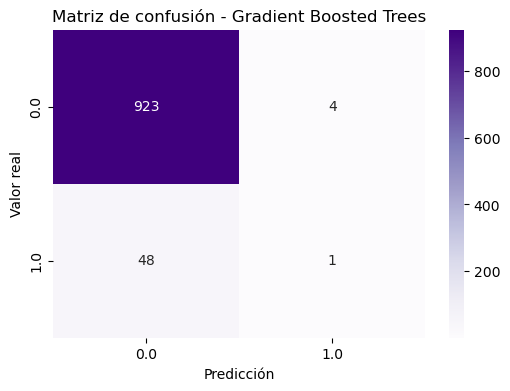

In [109]:
# Se dibuja la matriz de confusión
tablaGBT = pd.crosstab(matrizGBT['Derrame'],matrizGBT['prediction'],values=matrizGBT['count'],aggfunc='sum').reindex(index=[0.0,1.0],columns=[0.0,1.0],fill_value=0).fillna(0).astype(int)
plt.figure(figsize=(6,4))
sns.heatmap(tablaGBT,annot=True,fmt='d',cmap='Purples')
plt.title('Matriz de confusión - Gradient Boosted Trees')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [110]:
# Se calculan las métricas específicas de los casos con derrame
TN_GBT = int(tablaGBT.loc[0.0,0.0])
FP_GBT = int(tablaGBT.loc[0.0,1.0])
FN_GBT = int(tablaGBT.loc[1.0,0.0])
TP_GBT = int(tablaGBT.loc[1.0,1.0])
precision1GBT = TP_GBT/(TP_GBT+FP_GBT) if TP_GBT+FP_GBT>0 else 0
recall1GBT = TP_GBT/(TP_GBT+FN_GBT) if TP_GBT+FN_GBT>0 else 0
f1GBT = 2*precision1GBT*recall1GBT/(precision1GBT+recall1GBT) if precision1GBT+recall1GBT>0 else 0
print(f"TP={TP_GBT}, TN={TN_GBT}, FP={FP_GBT}, FN={FN_GBT}")
print(f"Precisión clase 1: {precision1GBT:.4f}")
print(f"Recall clase 1: {recall1GBT:.4f}")
print(f"F1 clase 1: {f1GBT:.4f}")

TP=1, TN=923, FP=4, FN=48
Precisión clase 1: 0.2000
Recall clase 1: 0.0204
F1 clase 1: 0.0370


In [111]:
# Se analizan los resultados numéricos del modelo Gradient Boosted Trees
print(f"Análisis: El modelo identificó {TP_GBT} de {TP_GBT+FN_GBT} pacientes con derrame ({recall1GBT*100:.2f}%).")
print(f"Se presentaron {FN_GBT} falsos negativos y {FP_GBT} falsos positivos.")
print(f"El accuracy fue {accuracyGBT*100:.2f}%, mientras que el recall de la clase 1 fue {recall1GBT*100:.2f}%.")
print('La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.')

Análisis: El modelo identificó 1 de 49 pacientes con derrame (2.04%).
Se presentaron 48 falsos negativos y 4 falsos positivos.
El accuracy fue 94.67%, mientras que el recall de la clase 1 fue 2.04%.
La cantidad de falsos negativos es fundamental para interpretar este resultado en un conjunto desbalanceado.


Distribución de probabilidades de Gradient Boosted Trees
Se analizan las probabilidades estimadas por el modelo para observar cómo se distribuyen las puntuaciones de los pacientes con y sin derrame.

In [130]:
# Se obtienen las probabilidades de Gradient Boosted Trees
probGBT = predGBT.select('Derrame', 'probability').toPandas()

# Se extrae la probabilidad de presentar derrame
probGBT['ProbDerrame'] = probGBT['probability'].apply(lambda x: float(x[1]))

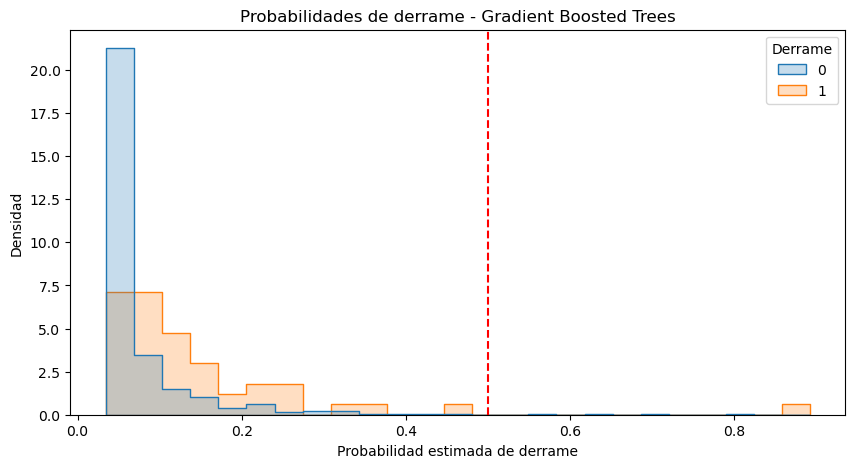

In [131]:
# Se grafica la distribución de probabilidades por clase
plt.figure(figsize=(10,5))
sns.histplot(data=probGBT, x='ProbDerrame',
             hue='Derrame', bins=25, stat='density',
             common_norm=False, element='step')

plt.axvline(0.5, color='red', linestyle='--')
plt.title('Probabilidades de derrame - Gradient Boosted Trees')
plt.xlabel('Probabilidad estimada de derrame')
plt.ylabel('Densidad')
plt.show()

In [132]:
# Se calculan las probabilidades promedio y máximas
print(probGBT.groupby('Derrame')['ProbDerrame']
      .agg(['mean','max','min']).round(4))


           mean     max     min
Derrame                        
0        0.0751  0.7937  0.0340
1        0.1480  0.8925  0.0458


Gradient Boosted Trees obtuvo un AUC-ROC de 0,8167 y una exactitud del 94,67 %. A diferencia de los otros modelos, consiguió identificar correctamente un paciente con derrame cerebral, pero dejó sin detectar los 48 casos positivos restantes.

El modelo también clasificó incorrectamente como positivos a cuatro pacientes que no habían presentado un derrame. Por lo tanto, aunque logró identificar un caso positivo, su recall fue de apenas el 2,04 % y su precisión para la clase positiva fue del 20 %.

La distribución de probabilidades permite analizar cómo se reparten las puntuaciones entre ambos grupos y comprobar si existe superposición. Los resultados muestran que este modelo presentó una ligera mejora en la detección de casos positivos frente a los demás, pero su capacidad para identificar pacientes con derrame sigue siendo muy limitada.

### **Comparación de los cuatro modelos**
Se resumen las métricas calculadas sobre el mismo conjunto de prueba, prestando atención a los pacientes con derrame.

In [112]:
# Se prepara la tabla comparativa de los modelos
comparacionModelos = pd.DataFrame({
 'Modelo':['Regresión Logística','Árbol de Decisión','Random Forest','Gradient Boosted Trees'],
 'Accuracy':[accurayRlog,accuracyArbol,accuracyBosque,accuracyGBT],
 'AUC-ROC':[ACURlog,aucArbol,aucBosque,aucGBT],
 'Precisión clase 1':[precision1RLog,precision1Arbol,precision1Bosque,precision1GBT],
 'Recall clase 1':[recall1RLog,recall1Arbol,recall1Bosque,recall1GBT],
 'F1 clase 1':[f1RLog,f1Arbol,f1Bosque,f1GBT],
 'Falsos negativos':[FN_RLog,FN_Arbol,FN_Bosque,FN_GBT]})
print(comparacionModelos.round(4).to_string(index=False))

                Modelo  Accuracy  AUC-ROC  Precisión clase 1  Recall clase 1  F1 clase 1  Falsos negativos
   Regresión Logística    0.9498   0.8214                0.0          0.0000       0.000                49
     Árbol de Decisión    0.9447   0.4717                0.0          0.0000       0.000                49
         Random Forest    0.9498   0.8265                0.0          0.0000       0.000                49
Gradient Boosted Trees    0.9467   0.8167                0.2          0.0204       0.037                48


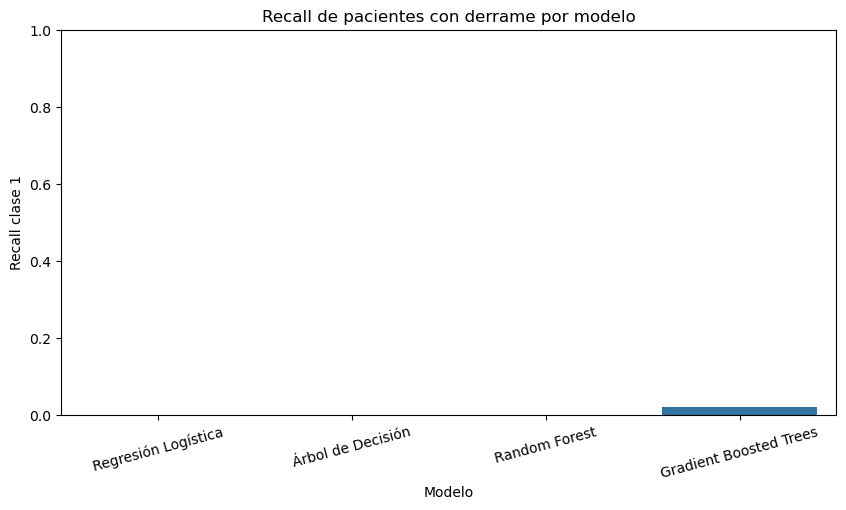

In [113]:
# Se grafican los resultados de recall para los pacientes con derrame
plt.figure(figsize=(10,5))
sns.barplot(data=comparacionModelos,x='Modelo',y='Recall clase 1')
plt.title('Recall de pacientes con derrame por modelo')
plt.xticks(rotation=15)
plt.ylim(0,1)
plt.show()

La comparación evidencia que los cuatro modelos presentan dificultades para identificar pacientes con derrame cerebral. La regresión logística, el árbol de decisión y Random Forest obtuvieron un recall del 0 %, lo que significa que ninguno logró reconocer los 49 casos positivos del conjunto de prueba.

Gradient Boosted Trees presentó el mejor resultado, con un recall del 2,04 %, equivalente a identificar correctamente un paciente de los 49 casos reales. Aunque supera a los demás modelos, su resultado sigue siendo muy bajo, por lo que ninguno demuestra una capacidad satisfactoria de detección de derrames con la configuración utilizada.

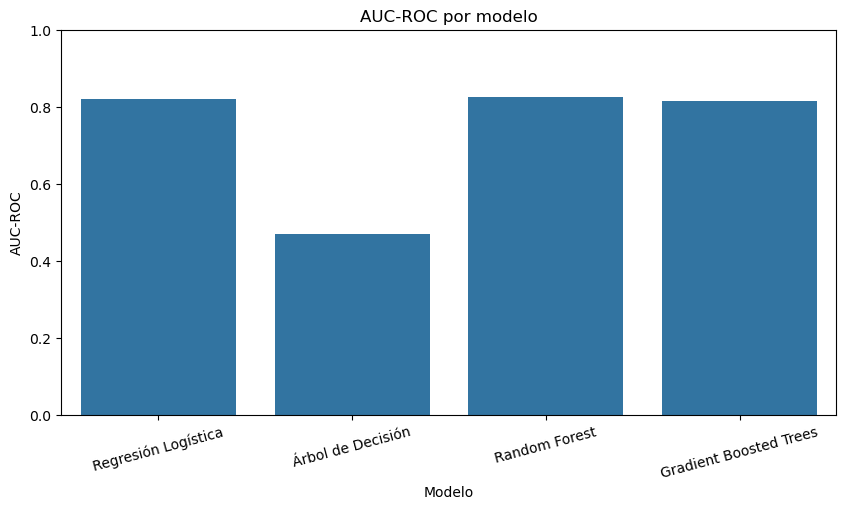

In [114]:
# Se compara el AUC-ROC de los modelos
plt.figure(figsize=(10,5))
sns.barplot(data=comparacionModelos,x='Modelo',y='AUC-ROC')
plt.title('AUC-ROC por modelo')
plt.xticks(rotation=15)
plt.ylim(0,1)
plt.show()

Random Forest obtuvo el mayor AUC-ROC con 0,8265, seguido de la regresión logística con 0,8214 y Gradient Boosted Trees con 0,8167. Los tres modelos presentan resultados similares en su capacidad para ordenar pacientes positivos por encima de los negativos según sus puntuaciones.

En cambio, el árbol de decisión obtuvo un AUC-ROC de 0,4717, considerablemente inferior a los demás. Esto indica que su capacidad de discriminación en el conjunto de prueba fue deficiente.

Sin embargo, los resultados de AUC-ROC deben interpretarse junto con el recall, ya que los tres modelos con mejores valores de AUC-ROC identificaron correctamente, entre todos, solamente un caso positivo al utilizar sus predicciones actuales.

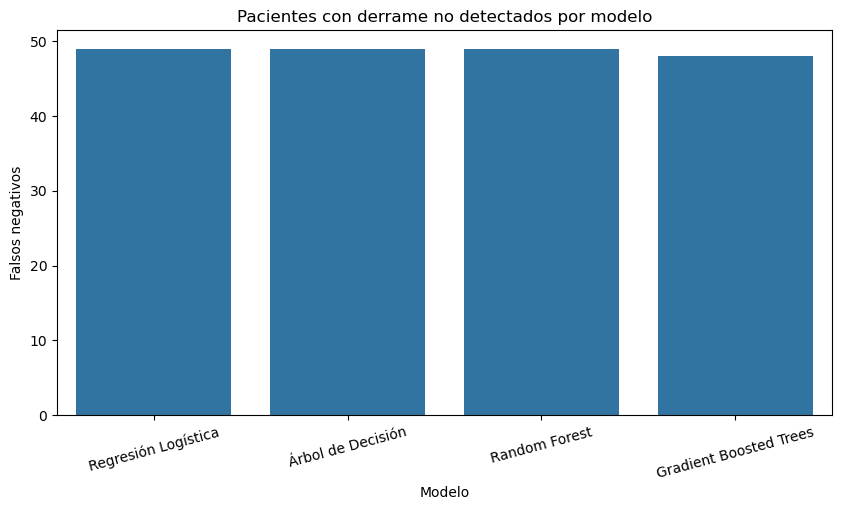

El mayor recall de la clase 1 fue de Gradient Boosted Trees con 2.04%.
El mejor AUC-ROC fue de Random Forest con 0.8265.
El menor número de falsos negativos fue 48, correspondiente a Gradient Boosted Trees.
La diferencia entre el mayor y el menor recall fue 2.04 puntos porcentuales.


In [115]:
# Se comparan los falsos negativos
plt.figure(figsize=(10,5))
sns.barplot(data=comparacionModelos,x='Modelo',y='Falsos negativos')
plt.title('Pacientes con derrame no detectados por modelo')
plt.xticks(rotation=15)
plt.show()# Se realiza una comparación numérica de los resultados
mejorRecall = comparacionModelos.loc[comparacionModelos['Recall clase 1'].idxmax()]
mejorAUC = comparacionModelos.loc[comparacionModelos['AUC-ROC'].idxmax()]
menorFN = comparacionModelos.loc[comparacionModelos['Falsos negativos'].idxmin()]
print(f"El mayor recall de la clase 1 fue de {mejorRecall['Modelo']} con {mejorRecall['Recall clase 1']*100:.2f}%.")
print(f"El mejor AUC-ROC fue de {mejorAUC['Modelo']} con {mejorAUC['AUC-ROC']:.4f}.")
print(f"El menor número de falsos negativos fue {int(menorFN['Falsos negativos'])}, correspondiente a {menorFN['Modelo']}.")
print(f"La diferencia entre el mayor y el menor recall fue {(comparacionModelos['Recall clase 1'].max()-comparacionModelos['Recall clase 1'].min())*100:.2f} puntos porcentuales.")

La gráfica muestra que la regresión logística, el árbol de decisión y Random Forest registraron 49 falsos negativos cada uno. Esto significa que todos los pacientes que realmente habían presentado un derrame fueron clasificados como negativos por estos tres modelos.

Gradient Boosted Trees presentó 48 falsos negativos, lo que representa una reducción de apenas un caso. Aunque fue el mejor resultado, sigue dejando sin identificar al 97,96 % de los pacientes con derrame.

Esta comparación es especialmente relevante porque demuestra que una exactitud cercana al 95 % no necesariamente significa que un modelo sea adecuado para reconocer la clase positiva cuando los datos están desbalanceados.

In [116]:
# Se realiza una comparación numérica de los resultados
mejorRecall = comparacionModelos.loc[comparacionModelos['Recall clase 1'].idxmax()]
mejorAUC = comparacionModelos.loc[comparacionModelos['AUC-ROC'].idxmax()]
menorFN = comparacionModelos.loc[comparacionModelos['Falsos negativos'].idxmin()]
print(f"El mayor recall de la clase 1 fue de {mejorRecall['Modelo']} con {mejorRecall['Recall clase 1']*100:.2f}%.")
print(f"El mejor AUC-ROC fue de {mejorAUC['Modelo']} con {mejorAUC['AUC-ROC']:.4f}.")
print(f"El menor número de falsos negativos fue {int(menorFN['Falsos negativos'])}, correspondiente a {menorFN['Modelo']}.")
print(f"La diferencia entre el mayor y el menor recall fue {(comparacionModelos['Recall clase 1'].max()-comparacionModelos['Recall clase 1'].min())*100:.2f} puntos porcentuales.")

El mayor recall de la clase 1 fue de Gradient Boosted Trees con 2.04%.
El mejor AUC-ROC fue de Random Forest con 0.8265.
El menor número de falsos negativos fue 48, correspondiente a Gradient Boosted Trees.
La diferencia entre el mayor y el menor recall fue 2.04 puntos porcentuales.


### **Balanceo de clases para mejorar la detección de derrames**

En los modelos anteriores se identificó un desbalance en la variable objetivo, debido a que la mayoría de los pacientes no presentó un derrame cerebral. Esto pudo influir en que los modelos obtuvieran valores altos de exactitud, pero identificaran muy pocos casos positivos.

Para estudiar este problema, se realiza un experimento utilizando pesos de clase, asignando mayor importancia a los pacientes con derrame durante el entrenamiento.

Se utiliza el mismo conjunto de entrenamiento y prueba de los modelos originales, sin modificar las transformaciones anteriores.

In [133]:
# Se cuentan los pacientes de cada clase en entrenamiento
cantidadSinDerrame = train.filter(F.col('Derrame') == 0).count()
cantidadConDerrame = train.filter(F.col('Derrame') == 1).count()

totalPacientes = cantidadSinDerrame + cantidadConDerrame

print("Pacientes sin derrame:", cantidadSinDerrame)
print("Pacientes con derrame:", cantidadConDerrame)
print("Total de pacientes:", totalPacientes)

Pacientes sin derrame: 3933
Pacientes con derrame: 200
Total de pacientes: 4133


In [134]:
# Se calculan los pesos de cada clase
pesoSinDerrame = totalPacientes / (2 * cantidadSinDerrame)
pesoConDerrame = totalPacientes / (2 * cantidadConDerrame)

print("Peso sin derrame:", round(pesoSinDerrame, 4))
print("Peso con derrame:", round(pesoConDerrame, 4))

Peso sin derrame: 0.5254
Peso con derrame: 10.3325


In [135]:
# Se agrega una columna con el peso de cada paciente
trainBalanceado = train.withColumn(
    'pesoClase',
    F.when(F.col('Derrame') == 1, pesoConDerrame)
     .otherwise(pesoSinDerrame)
)

# Se observan los pesos asignados a cada clase
trainBalanceado.groupBy('Derrame', 'pesoClase').count().show()


+-------+------------------+-----+
|Derrame|         pesoClase|count|
+-------+------------------+-----+
|      1|           10.3325|  200|
|      0|0.5254258835494533| 3933|
+-------+------------------+-----+



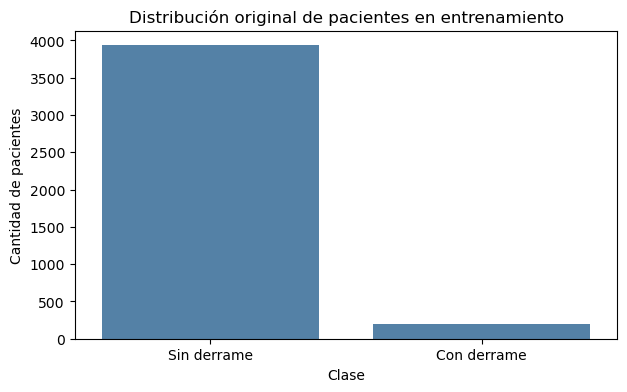

In [136]:
# Se grafica la distribución original de las clases
datosBalanceo = pd.DataFrame({
    'Clase': ['Sin derrame', 'Con derrame'],
    'Cantidad': [cantidadSinDerrame, cantidadConDerrame]
})

plt.figure(figsize=(7,4))
sns.barplot(data=datosBalanceo, x='Clase', y='Cantidad',
            color='steelblue')

plt.title('Distribución original de pacientes en entrenamiento')
plt.xlabel('Clase')
plt.ylabel('Cantidad de pacientes')
plt.show()


La distribución original muestra que existe una diferencia considerable entre la cantidad de pacientes con y sin derrame cerebral. Esta desigualdad puede provocar que los modelos aprendan principalmente los patrones de la clase mayoritaria.

Para estudiar este comportamiento, se asignaron pesos diferentes a las dos clases durante el entrenamiento. Los pacientes con derrame reciben mayor peso porque representan una proporción pequeña del conjunto de datos. Este procedimiento no aumenta ni elimina registros, sino que modifica la importancia de cada observación durante el aprendizaje.

### Regresión Logística con balanceo de clases

Se entrena nuevamente el modelo de Regresión Logística, utilizando los pesos calculados anteriormente. El objetivo es determinar si al dar mayor importancia a los pacientes con derrame mejora la capacidad del modelo para identificar casos positivos.

In [138]:
# Se instancia la regresión logística con pesos de clase
RegreLogBalanceada = LogisticRegression(
    featuresCol='independientes',
    labelCol='Derrame',
    weightCol='pesoClase'
)


In [139]:
# Se entrena el modelo con los datos balanceados
modeloRegLogBalanceado = RegreLogBalanceada.fit(trainBalanceado)


In [140]:
# Se realizan las predicciones sobre los datos de prueba
predRLogBalanceada = modeloRegLogBalanceado.transform(test)

predRLogBalanceada.select(
    'Derrame', 'prediction', 'probability'
).show(5, False)

+-------+----------+----------------------------------------+
|Derrame|prediction|probability                             |
+-------+----------+----------------------------------------+
|0      |1.0       |[0.08672795940934994,0.91327204059065]  |
|0      |0.0       |[0.7973316759487956,0.20266832405120438]|
|0      |1.0       |[0.41485703207116226,0.5851429679288378]|
|0      |1.0       |[0.1450938144366888,0.8549061855633112] |
|0      |0.0       |[0.7346984077509614,0.2653015922490386] |
+-------+----------+----------------------------------------+
only showing top 5 rows



In [141]:
# Se calculan las métricas de la regresión logística balanceada
aucRLogBal = BinaryClassificationEvaluator(
    labelCol='Derrame',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
).evaluate(predRLogBalanceada)

accuracyRLogBal = MulticlassClassificationEvaluator(
    labelCol='Derrame',
    metricName='accuracy'
).evaluate(predRLogBalanceada)

print(f"AUC-ROC: {aucRLogBal:.4f}")
print(f"Accuracy: {accuracyRLogBal*100:.2f}%")

AUC-ROC: 0.8196
Accuracy: 75.10%


In [142]:
# Se obtiene la matriz de confusión
matrizRLogBal = predRLogBalanceada.groupBy(
    'Derrame', 'prediction'
).count().toPandas()

tablaRLogBal = pd.crosstab(
    matrizRLogBal['Derrame'],
    matrizRLogBal['prediction'],
    values=matrizRLogBal['count'],
    aggfunc='sum'
).reindex(
    index=[0.0,1.0],
    columns=[0.0,1.0],
    fill_value=0
).fillna(0).astype(int)

print(tablaRLogBal)


prediction  0.0  1.0
Derrame             
0.0         697  230
1.0          13   36


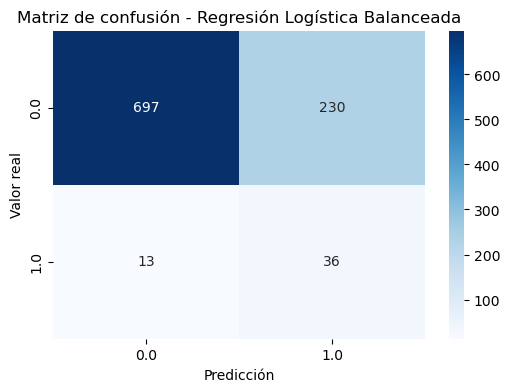

In [143]:
# Se grafica la matriz de confusión
plt.figure(figsize=(6,4))
sns.heatmap(tablaRLogBal, annot=True, fmt='d', cmap='Blues')

plt.title('Matriz de confusión - Regresión Logística Balanceada')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()


In [144]:
# Se calculan los verdaderos y falsos positivos y negativos
TN_RLogBal = int(tablaRLogBal.loc[0.0,0.0])
FP_RLogBal = int(tablaRLogBal.loc[0.0,1.0])
FN_RLogBal = int(tablaRLogBal.loc[1.0,0.0])
TP_RLogBal = int(tablaRLogBal.loc[1.0,1.0])

# Se calcula precision, recall y F1 para la clase 1
precisionRLogBal = TP_RLogBal/(TP_RLogBal+FP_RLogBal) if TP_RLogBal+FP_RLogBal>0 else 0
recallRLogBal = TP_RLogBal/(TP_RLogBal+FN_RLogBal) if TP_RLogBal+FN_RLogBal>0 else 0
f1RLogBal = 2*precisionRLogBal*recallRLogBal/(precisionRLogBal+recallRLogBal) if precisionRLogBal+recallRLogBal>0 else 0

print(f"TP={TP_RLogBal}, TN={TN_RLogBal}, FP={FP_RLogBal}, FN={FN_RLogBal}")
print(f"Precisión clase 1: {precisionRLogBal:.4f}")
print(f"Recall clase 1: {recallRLogBal:.4f}")
print(f"F1 clase 1: {f1RLogBal:.4f}")

TP=36, TN=697, FP=230, FN=13
Precisión clase 1: 0.1353
Recall clase 1: 0.7347
F1 clase 1: 0.2286


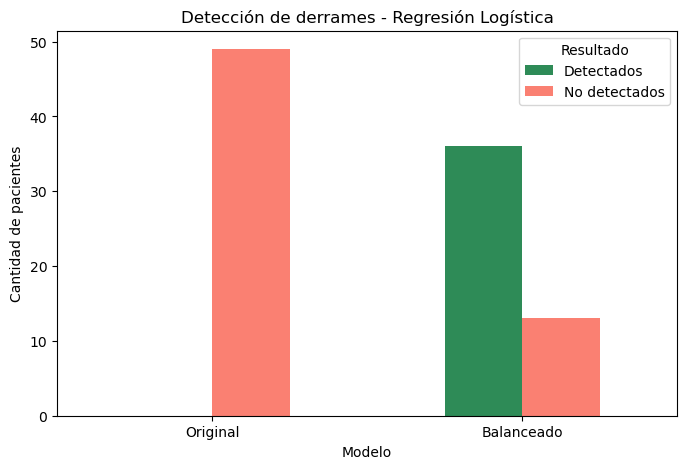

In [145]:
# Se comparan los resultados antes y después del balanceo
datosComparacionRLog = pd.DataFrame({
    'Modelo': ['Original', 'Balanceado'],
    'Detectados': [TP_RLog, TP_RLogBal],
    'No detectados': [FN_RLog, FN_RLogBal]
})

datosComparacionRLog = datosComparacionRLog.set_index('Modelo')

datosComparacionRLog.plot(
    kind='bar',
    figsize=(8,5),
    color=['seagreen','salmon']
)

plt.title('Detección de derrames - Regresión Logística')
plt.xlabel('Modelo')
plt.ylabel('Cantidad de pacientes')
plt.xticks(rotation=0)
plt.legend(title='Resultado')
plt.show()


Se peude evidenciar que el modelo original no detectaba ningún caso positivo, mientras que el modelo balanceado consiguió identificar 36 de los 49 pacientes con derrame.

In [146]:
# Se realiza una comparación numérica de los resultados
print(f"Casos detectados antes: {TP_RLog}")
print(f"Casos detectados después: {TP_RLogBal}")

print(f"Falsos negativos antes: {FN_RLog}")
print(f"Falsos negativos después: {FN_RLogBal}")

print(f"Falsos positivos antes: {FP_RLog}")
print(f"Falsos positivos después: {FP_RLogBal}")

print(f"Recall antes: {recall1RLog*100:.2f}%")
print(f"Recall después: {recallRLogBal*100:.2f}%")

Casos detectados antes: 0
Casos detectados después: 36
Falsos negativos antes: 49
Falsos negativos después: 13
Falsos positivos antes: 0
Falsos positivos después: 230
Recall antes: 0.00%
Recall después: 73.47%


### Análisis de la Regresión Logística con balanceo

La aplicación de pesos de clase produjo una mejora considerable en la detección de pacientes con derrame cerebral. Mientras que la regresión logística original no identificó correctamente ninguno de los 49 casos positivos, el modelo balanceado logró detectar 36 pacientes, alcanzando un recall del 73,47 %.

Esta mejora también se refleja en la reducción de falsos negativos, que pasaron de 49 a 13. Sin embargo, el modelo balanceado clasificó incorrectamente como positivos a 230 pacientes que no habían presentado un derrame. Como consecuencia, la precisión de la clase positiva fue del 13,53 %, lo que significa que aproximadamente 14 de cada 100 pacientes señalados como positivos realmente habían presentado el evento.

La exactitud disminuyó del 94,98 % al 75,10 %, mientras que el AUC-ROC cambió ligeramente de 0,8214 a 0,8196. Por lo tanto, el balanceo permitió detectar una proporción mucho mayor de los casos positivos, aunque aumentó considerablemente las falsas alarmas.

### Random Forest con balanceo de clases
Se entrena nuevamente Random Forest utilizando pesos de clase. Se conservan los 50 árboles y la profundidad máxima de 5 utilizados en el modelo original, con el fin de estudiar el efecto del balanceo sobre los resultados.

In [150]:
# Se instancia Random Forest con pesos de clase
clasificadorBosqueBal = RandomForestClassifier(
    featuresCol='independientes',
    labelCol='Derrame',
    numTrees=50,
    maxDepth=5,
    weightCol='pesoClase'
)

In [151]:
# Se entrena el modelo Random Forest balanceado
modeloBosqueBal = clasificadorBosqueBal.fit(trainBalanceado)

In [152]:
# Se hacen las predicciones sobre el conjunto de prueba
predBosqueBal = modeloBosqueBal.transform(test)

predBosqueBal.select(
    'Derrame', 'prediction', 'probability'
).show(5, False)


+-------+----------+----------------------------------------+
|Derrame|prediction|probability                             |
+-------+----------+----------------------------------------+
|0      |1.0       |[0.21071846138011088,0.7892815386198891]|
|0      |0.0       |[0.877775896904527,0.12222410309547307] |
|0      |1.0       |[0.39790841156273177,0.6020915884372683]|
|0      |1.0       |[0.2274188620292619,0.7725811379707381] |
|0      |0.0       |[0.8467029032245634,0.15329709677543654]|
+-------+----------+----------------------------------------+
only showing top 5 rows



In [153]:

# Se calculan las métricas de Random Forest balanceado
aucBosqueBal = BinaryClassificationEvaluator(
    labelCol='Derrame',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
).evaluate(predBosqueBal)

accuracyBosqueBal = MulticlassClassificationEvaluator(
    labelCol='Derrame',
    metricName='accuracy'
).evaluate(predBosqueBal)

print(f"AUC-ROC: {aucBosqueBal:.4f}")
print(f"Accuracy: {accuracyBosqueBal*100:.2f}%")


AUC-ROC: 0.8291
Accuracy: 76.13%


In [154]:
# Se obtiene la matriz de confusión
matrizBosqueBal = predBosqueBal.groupBy(
    'Derrame', 'prediction'
).count().toPandas()

tablaBosqueBal = pd.crosstab(
    matrizBosqueBal['Derrame'],
    matrizBosqueBal['prediction'],
    values=matrizBosqueBal['count'],
    aggfunc='sum'
).reindex(
    index=[0.0,1.0],
    columns=[0.0,1.0],
    fill_value=0
).fillna(0).astype(int)

print(tablaBosqueBal)


prediction  0.0  1.0
Derrame             
0.0         708  219
1.0          14   35


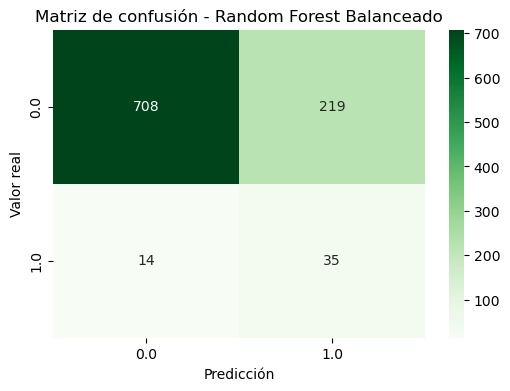

In [155]:
# Se grafica la matriz de confusión
plt.figure(figsize=(6,4))
sns.heatmap(tablaBosqueBal, annot=True, fmt='d', cmap='Greens')

plt.title('Matriz de confusión - Random Forest Balanceado')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [156]:
# Se calculan los verdaderos y falsos positivos y negativos
TN_BosqueBal = int(tablaBosqueBal.loc[0.0,0.0])
FP_BosqueBal = int(tablaBosqueBal.loc[0.0,1.0])
FN_BosqueBal = int(tablaBosqueBal.loc[1.0,0.0])
TP_BosqueBal = int(tablaBosqueBal.loc[1.0,1.0])

# Se calculan las métricas de la clase positiva
precisionBosqueBal = TP_BosqueBal/(TP_BosqueBal+FP_BosqueBal) if TP_BosqueBal+FP_BosqueBal>0 else 0
recallBosqueBal = TP_BosqueBal/(TP_BosqueBal+FN_BosqueBal) if TP_BosqueBal+FN_BosqueBal>0 else 0
f1BosqueBal = 2*precisionBosqueBal*recallBosqueBal/(precisionBosqueBal+recallBosqueBal) if precisionBosqueBal+recallBosqueBal>0 else 0

print(f"TP={TP_BosqueBal}, TN={TN_BosqueBal}, FP={FP_BosqueBal}, FN={FN_BosqueBal}")
print(f"Precisión clase 1: {precisionBosqueBal:.4f}")
print(f"Recall clase 1: {recallBosqueBal:.4f}")
print(f"F1 clase 1: {f1BosqueBal:.4f}")


TP=35, TN=708, FP=219, FN=14
Precisión clase 1: 0.1378
Recall clase 1: 0.7143
F1 clase 1: 0.2310


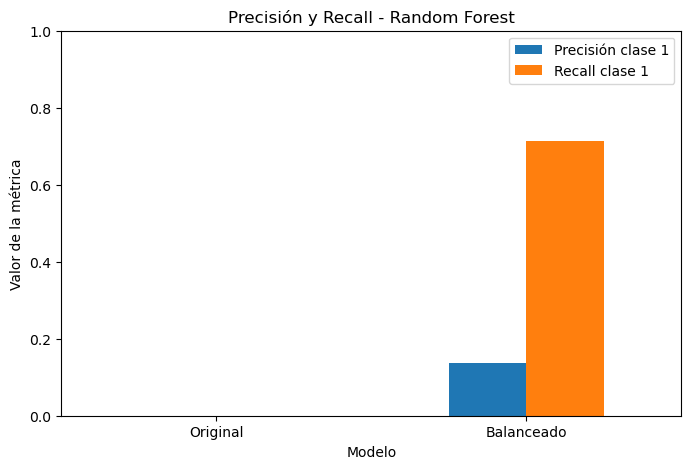

In [157]:
# Se comparan las métricas antes y después del balanceo
comparacionBosque = pd.DataFrame({
    'Modelo': ['Original', 'Balanceado'],
    'Precisión clase 1': [precision1Bosque, precisionBosqueBal],
    'Recall clase 1': [recall1Bosque, recallBosqueBal]
})

comparacionBosque = comparacionBosque.set_index('Modelo')

comparacionBosque.plot(kind='bar', figsize=(8,5))

plt.title('Precisión y Recall - Random Forest')
plt.ylabel('Valor de la métrica')
plt.xlabel('Modelo')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show()


La comparación de precisión y recall evidencia que el balanceo mejoró considerablemente la sensibilidad del modelo, pero todavía existe una cantidad importante de falsas alarmas.

In [158]:
# Se comparan los resultados del modelo
print(f"Casos detectados antes: {TP_Bosque}")
print(f"Casos detectados después: {TP_BosqueBal}")

print(f"Falsos negativos antes: {FN_Bosque}")
print(f"Falsos negativos después: {FN_BosqueBal}")

print(f"Falsos positivos antes: {FP_Bosque}")
print(f"Falsos positivos después: {FP_BosqueBal}")

print(f"Recall antes: {recall1Bosque*100:.2f}%")
print(f"Recall después: {recallBosqueBal*100:.2f}%")

Casos detectados antes: 0
Casos detectados después: 35
Falsos negativos antes: 49
Falsos negativos después: 14
Falsos positivos antes: 0
Falsos positivos después: 219
Recall antes: 0.00%
Recall después: 71.43%


### Análisis de Random Forest con balanceo

El balanceo de clases permitió mejorar significativamente la identificación de pacientes con derrame cerebral. En su versión original, Random Forest clasificó correctamente los 927 pacientes sin derrame, pero no detectó ninguno de los 49 casos positivos. Después de aplicar los pesos de clase, el modelo consiguió identificar correctamente 35 pacientes con derrame.

El recall aumentó del 0 % al 71,43 %, mientras que los falsos negativos disminuyeron de 49 a 14. Este resultado demuestra que el modelo balanceado logró reconocer una proporción considerablemente mayor de los pacientes pertenecientes a la clase minoritaria. Esta mejora estuvo acompañada de 219 falsos positivos, es decir, pacientes sin derrame que fueron clasificados incorrectamente como positivos. Por esta razón, la precisión de la clase positiva fue del 13,78 % y la exactitud general disminuyó del 94,98 % al 76,13 %.

Por otra parte, el AUC-ROC aumentó ligeramente de 0,8265 a 0,8291. Aunque esta diferencia es pequeña, Random Forest balanceado conservó una capacidad de discriminación similar a la del modelo original, mientras que consiguió detectar muchos más casos positivos.

### Gradient Boosted Trees con balanceo de clases
Se entrena nuevamente Gradient Boosted Trees utilizando los pesos asignados a las clases. Se conservan las 20 iteraciones y la profundidad máxima de 5 del modelo original.
El objetivo es determinar si el balanceo permite mejorar la detección de pacientes con derrame, considerando que el modelo original solamente consiguió identificar correctamente uno de los 49 casos positivos.

In [161]:
# Se instancia Gradient Boosted Trees con pesos de clase
clasificadorGBTBal = GBTClassifier(
    featuresCol='independientes',
    labelCol='Derrame',
    maxIter=20,
    maxDepth=5,
    weightCol='pesoClase'
)


In [162]:
# Se entrena el modelo con los datos balanceados
modeloGBTBal = clasificadorGBTBal.fit(trainBalanceado)


In [163]:
# Se realizan las predicciones sobre los datos de prueba
predGBTBal = modeloGBTBal.transform(test)

predGBTBal.select(
    'Derrame', 'prediction', 'probability'
).show(5, False)


+-------+----------+-----------------------------------------+
|Derrame|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.8966290216256242,0.10337097837437581] |
|0      |0.0       |[0.9586573687236769,0.041342631276323094]|
|0      |1.0       |[0.23324461940135316,0.7667553805986469] |
|0      |1.0       |[0.15854140468107017,0.8414585953189299] |
|0      |0.0       |[0.9074869798701004,0.09251302012989959] |
+-------+----------+-----------------------------------------+
only showing top 5 rows



In [164]:
# Se calculan las métricas de Gradient Boosted Trees balanceado
aucGBTBal = BinaryClassificationEvaluator(
    labelCol='Derrame',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
).evaluate(predGBTBal)

accuracyGBTBal = MulticlassClassificationEvaluator(
    labelCol='Derrame',
    metricName='accuracy'
).evaluate(predGBTBal)

print(f"AUC-ROC: {aucGBTBal:.4f}")
print(f"Accuracy: {accuracyGBTBal*100:.2f}%")

AUC-ROC: 0.8205
Accuracy: 81.56%


In [165]:
# Se obtiene la matriz de confusión
matrizGBTBal = predGBTBal.groupBy(
    'Derrame', 'prediction'
).count().toPandas()

tablaGBTBal = pd.crosstab(
    matrizGBTBal['Derrame'],
    matrizGBTBal['prediction'],
    values=matrizGBTBal['count'],
    aggfunc='sum'
).reindex(
    index=[0.0,1.0],
    columns=[0.0,1.0],
    fill_value=0
).fillna(0).astype(int)

print(tablaGBTBal)

prediction  0.0  1.0
Derrame             
0.0         766  161
1.0          19   30


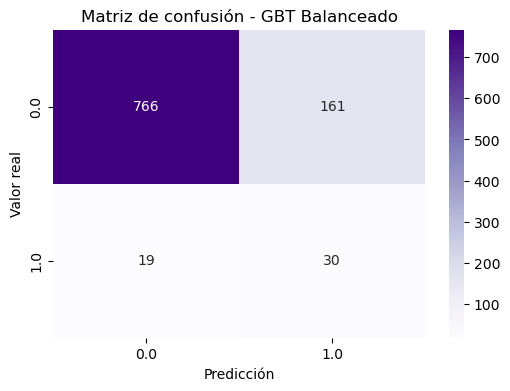

In [166]:
# Se grafica la matriz de confusión
plt.figure(figsize=(6,4))
sns.heatmap(tablaGBTBal, annot=True, fmt='d', cmap='Purples')

plt.title('Matriz de confusión - GBT Balanceado')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()


In [167]:
# Se calculan los verdaderos y falsos positivos y negativos
TN_GBTBal = int(tablaGBTBal.loc[0.0,0.0])
FP_GBTBal = int(tablaGBTBal.loc[0.0,1.0])
FN_GBTBal = int(tablaGBTBal.loc[1.0,0.0])
TP_GBTBal = int(tablaGBTBal.loc[1.0,1.0])

# Se calculan las métricas específicas de la clase positiva
precisionGBTBal = TP_GBTBal/(TP_GBTBal+FP_GBTBal) if TP_GBTBal+FP_GBTBal>0 else 0
recallGBTBal = TP_GBTBal/(TP_GBTBal+FN_GBTBal) if TP_GBTBal+FN_GBTBal>0 else 0
f1GBTBal = 2*precisionGBTBal*recallGBTBal/(precisionGBTBal+recallGBTBal) if precisionGBTBal+recallGBTBal>0 else 0

print(f"TP={TP_GBTBal}, TN={TN_GBTBal}, FP={FP_GBTBal}, FN={FN_GBTBal}")
print(f"Precisión clase 1: {precisionGBTBal:.4f}")
print(f"Recall clase 1: {recallGBTBal:.4f}")
print(f"F1 clase 1: {f1GBTBal:.4f}")


TP=30, TN=766, FP=161, FN=19
Precisión clase 1: 0.1571
Recall clase 1: 0.6122
F1 clase 1: 0.2500


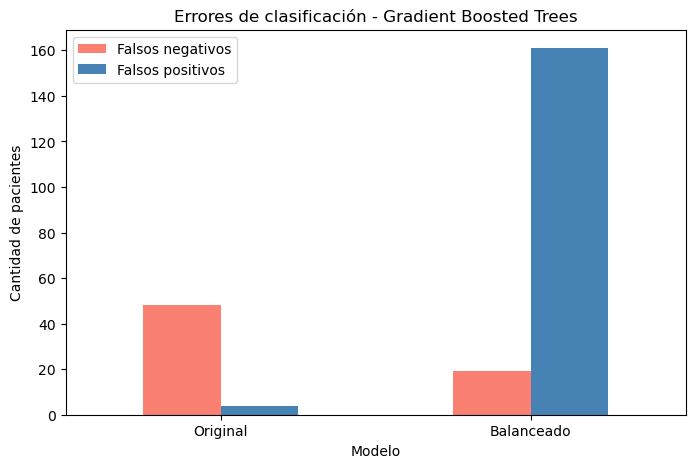

In [168]:
# Se comparan los errores antes y después del balanceo
comparacionGBT = pd.DataFrame({
    'Modelo': ['Original', 'Balanceado'],
    'Falsos negativos': [FN_GBT, FN_GBTBal],
    'Falsos positivos': [FP_GBT, FP_GBTBal]
})

comparacionGBT = comparacionGBT.set_index('Modelo')

comparacionGBT.plot(
    kind='bar',
    figsize=(8,5),
    color=['salmon','steelblue']
)

plt.title('Errores de clasificación - Gradient Boosted Trees')
plt.ylabel('Cantidad de pacientes')
plt.xlabel('Modelo')
plt.xticks(rotation=0)
plt.show()


In [169]:
# Se realiza una comparación de resultados
print(f"Casos detectados antes: {TP_GBT}")
print(f"Casos detectados después: {TP_GBTBal}")

print(f"Falsos negativos antes: {FN_GBT}")
print(f"Falsos negativos después: {FN_GBTBal}")

print(f"Falsos positivos antes: {FP_GBT}")
print(f"Falsos positivos después: {FP_GBTBal}")

print(f"Recall antes: {recall1GBT*100:.2f}%")
print(f"Recall después: {recallGBTBal*100:.2f}%")


Casos detectados antes: 1
Casos detectados después: 30
Falsos negativos antes: 48
Falsos negativos después: 19
Falsos positivos antes: 4
Falsos positivos después: 161
Recall antes: 2.04%
Recall después: 61.22%


### Comparación de modelos originales y balanceados
Se comparan los resultados de los cuatro modelos originales y los tres modelos entrenados con pesos de clase.
Se utilizan las mismas métricas de evaluación para identificar posibles mejoras en la detección de pacientes con derrame cerebral, prestando especial atención al recall, la precisión y los falsos negativos.

In [170]:
# Se construye la tabla comparativa de los siete modelos
comparacionFinal = pd.DataFrame({
    'Modelo': [
        'Regresión Logística',
        'Árbol de Decisión',
        'Random Forest',
        'Gradient Boosted Trees',
        'Regresión Logística Balanceada',
        'Random Forest Balanceado',
        'GBT Balanceado'
    ],
    'Accuracy': [
        accurayRlog, accuracyArbol, accuracyBosque, accuracyGBT,
        accuracyRLogBal, accuracyBosqueBal, accuracyGBTBal
    ],
    'AUC-ROC': [
        ACURlog, aucArbol, aucBosque, aucGBT,
        aucRLogBal, aucBosqueBal, aucGBTBal
    ],
    'Precisión clase 1': [
        precision1RLog, precision1Arbol, precision1Bosque,
        precision1GBT, precisionRLogBal, precisionBosqueBal, precisionGBTBal
    ],
    'Recall clase 1': [
        recall1RLog, recall1Arbol, recall1Bosque,
        recall1GBT, recallRLogBal, recallBosqueBal, recallGBTBal
    ],
    'F1 clase 1': [
        f1RLog, f1Arbol, f1Bosque, f1GBT,
        f1RLogBal, f1BosqueBal, f1GBTBal
    ],
    'Falsos positivos': [
        FP_RLog, FP_Arbol, FP_Bosque, FP_GBT,
        FP_RLogBal, FP_BosqueBal, FP_GBTBal
    ],
    'Falsos negativos': [
        FN_RLog, FN_Arbol, FN_Bosque, FN_GBT,
        FN_RLogBal, FN_BosqueBal, FN_GBTBal
    ]
})

print(comparacionFinal.round(4).to_string(index=False))


                        Modelo  Accuracy  AUC-ROC  Precisión clase 1  Recall clase 1  F1 clase 1  Falsos positivos  Falsos negativos
           Regresión Logística    0.9498   0.8214             0.0000          0.0000      0.0000                 0                49
             Árbol de Decisión    0.9447   0.4717             0.0000          0.0000      0.0000                 5                49
                 Random Forest    0.9498   0.8265             0.0000          0.0000      0.0000                 0                49
        Gradient Boosted Trees    0.9467   0.8167             0.2000          0.0204      0.0370                 4                48
Regresión Logística Balanceada    0.7510   0.8196             0.1353          0.7347      0.2286               230                13
      Random Forest Balanceado    0.7613   0.8291             0.1378          0.7143      0.2310               219                14
                GBT Balanceado    0.8156   0.8205             0.1571 

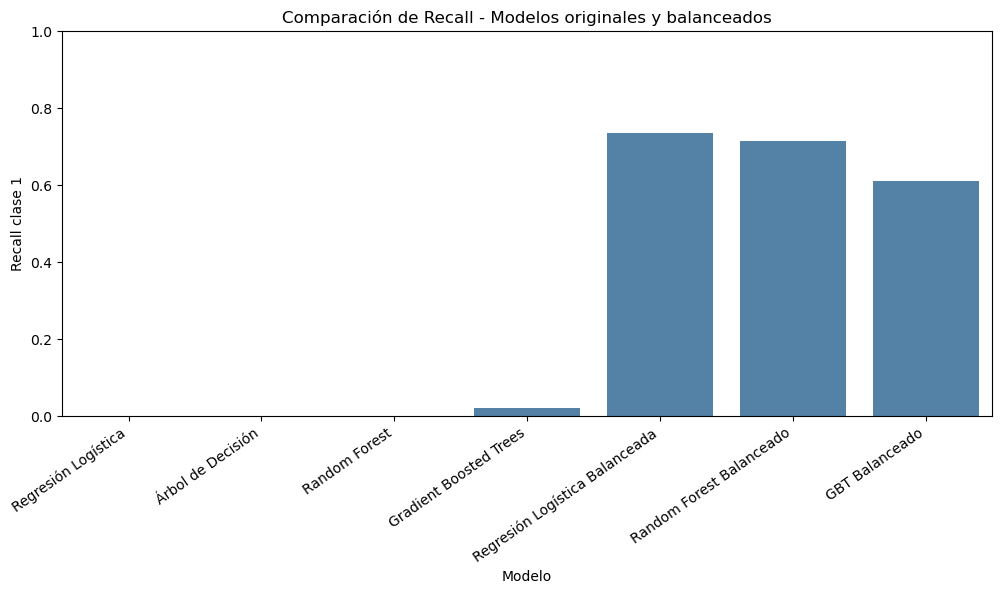

In [171]:
# Se compara el recall de todos los modelos
plt.figure(figsize=(12,5))

sns.barplot(
    data=comparacionFinal,
    x='Modelo',
    y='Recall clase 1',
    color='steelblue'
)

plt.title('Comparación de Recall - Modelos originales y balanceados')
plt.xlabel('Modelo')
plt.ylabel('Recall clase 1')
plt.xticks(rotation=35, ha='right')
plt.ylim(0,1)
plt.show()


La gráfica muestra una diferencia importante entre los modelos originales y los modelos balanceados. La regresión logística, el árbol de decisión y Random Forest obtuvieron un recall del 0 %, lo que significa que ninguno consiguió identificar correctamente a los 49 pacientes con derrame cerebral. Por su parte, Gradient Boosted Trees original alcanzó un recall del 2,04 %, detectando solamente un caso positivo.

Después de aplicar el balanceo de clases, los resultados mejoraron considerablemente. La regresión logística balanceada obtuvo el mayor recall, con un 73,47 %, identificando correctamente 36 de los 49 pacientes con derrame. Le siguió Random Forest balanceado con un 71,43 %, equivalente a 35 pacientes, mientras que GBT balanceado alcanzó un 61,22 %, detectando 30 casos positivos.

Estos resultados muestran que el balanceo mediante pesos permitió que los tres modelos identificaran una proporción mucho mayor de pacientes con derrame. Sin embargo, un recall elevado no garantiza que todas las predicciones positivas sean correctas, por lo que también es necesario analizar la precisión y los falsos positivos.

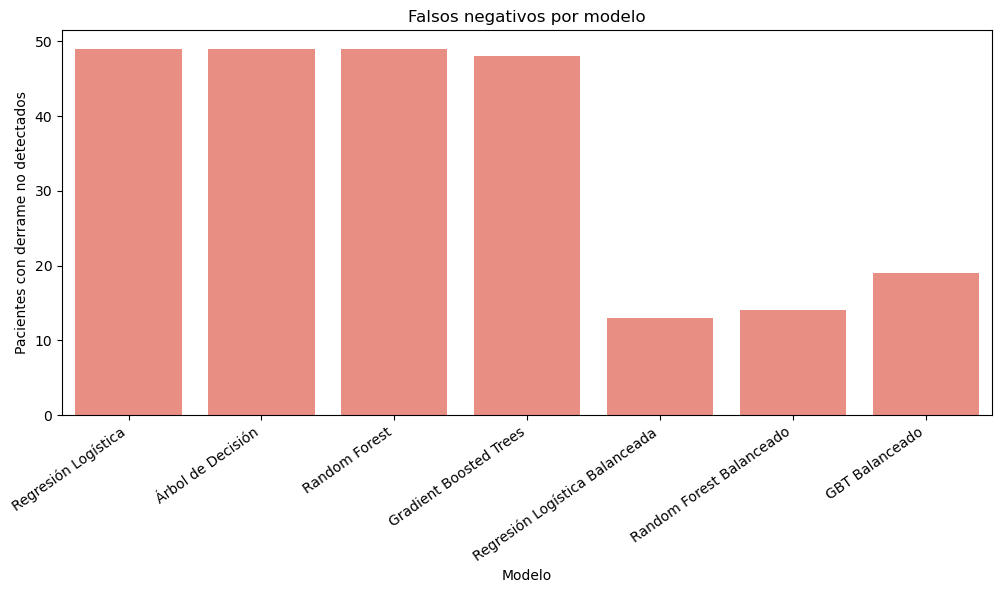

In [172]:
# Se comparan los falsos negativos de los siete modelos
plt.figure(figsize=(12,5))

sns.barplot(
    data=comparacionFinal,
    x='Modelo',
    y='Falsos negativos',
    color='salmon'
)

plt.title('Falsos negativos por modelo')
plt.xlabel('Modelo')
plt.ylabel('Pacientes con derrame no detectados')
plt.xticks(rotation=35, ha='right')
plt.show()

La gráfica evidencia que los modelos originales presentaron dificultades para reconocer los casos positivos. La regresión logística, el árbol de decisión y Random Forest registraron 49 falsos negativos cada uno, es decir, clasificaron como negativos a todos los pacientes que realmente habían presentado un derrame. Gradient Boosted Trees tuvo un resultado ligeramente mejor, con 48 falsos negativos.

Después del balanceo, la regresión logística redujo los falsos negativos de 49 a 13, lo que representa 36 pacientes adicionales identificados correctamente. Random Forest pasó de 49 a 14 falsos negativos, mientras que GBT disminuyó de 48 a 19.

La regresión logística balanceada obtuvo la menor cantidad de falsos negativos, seguida de Random Forest balanceado. Esto demuestra que asignar mayor peso a la clase minoritaria permitió disminuir considerablemente los casos positivos que los modelos no lograban identificar. No obstante, todavía existen pacientes con derrame que son clasificados incorrectamente, por lo que los modelos no presentan una detección completa.

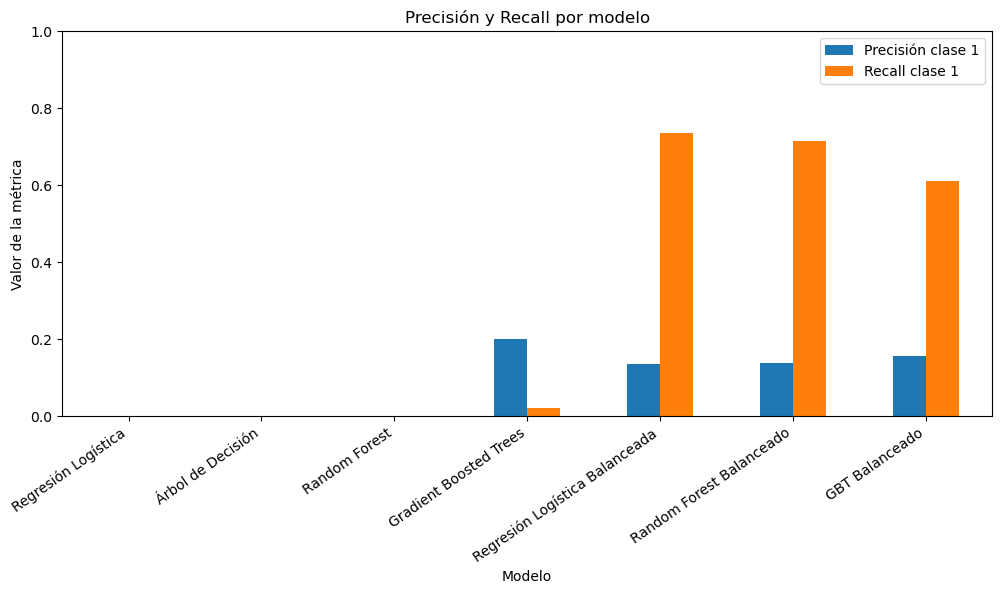

In [173]:
# Se comparan la precisión y el recall de los modelos
datosPrecisionRecall = comparacionFinal.set_index('Modelo')[
    ['Precisión clase 1', 'Recall clase 1']
]

datosPrecisionRecall.plot(
    kind='bar',
    figsize=(12,5)
)

plt.title('Precisión y Recall por modelo')
plt.xlabel('Modelo')
plt.ylabel('Valor de la métrica')
plt.xticks(rotation=35, ha='right')
plt.ylim(0,1)
plt.show()


La gráfica permite observar que el balanceo mejoró considerablemente el recall de los modelos, pero la precisión de la clase positiva continuó siendo baja.

La regresión logística balanceada alcanzó un recall del 73,47 % y una precisión del 13,53 %. Esto significa que logró detectar 36 pacientes con derrame, pero también clasificó incorrectamente como positivos a 230 pacientes que no habían presentado el evento.

Random Forest balanceado obtuvo un recall del 71,43 % y una precisión del 13,78 %, con 35 casos positivos detectados y 219 falsos positivos.

Por su parte, GBT balanceado presentó un recall menor, del 61,22 %, pero alcanzó la mayor precisión entre los modelos balanceados, con un 15,71 %. Este modelo identificó correctamente 30 pacientes con derrame y produjo 161 falsos positivos, una cantidad inferior a la registrada por los otros dos modelos balanceados.

Los resultados muestran que la regresión logística balanceada consiguió identificar más pacientes con derrame, mientras que GBT balanceado generó menos falsas alarmas. Por lo tanto, la elección del modelo depende de la importancia que se otorgue a detectar más casos positivos frente a reducir las clasificaciones incorrectas.

In [174]:
# Se identifican los mejores resultados de la comparación
mejorRecallFinal = comparacionFinal.loc[
    comparacionFinal['Recall clase 1'].idxmax()
]

mejorF1Final = comparacionFinal.loc[
    comparacionFinal['F1 clase 1'].idxmax()
]

mejorAUCFinal = comparacionFinal.loc[
    comparacionFinal['AUC-ROC'].idxmax()
]

print("Modelo con mayor Recall:", mejorRecallFinal['Modelo'])
print(f"Recall: {mejorRecallFinal['Recall clase 1']*100:.2f}%")

print("\nModelo con mayor F1:", mejorF1Final['Modelo'])
print(f"F1: {mejorF1Final['F1 clase 1']:.4f}")

print("\nModelo con mayor AUC-ROC:", mejorAUCFinal['Modelo'])
print(f"AUC-ROC: {mejorAUCFinal['AUC-ROC']:.4f}")


Modelo con mayor Recall: Regresión Logística Balanceada
Recall: 73.47%

Modelo con mayor F1: GBT Balanceado
F1: 0.2500

Modelo con mayor AUC-ROC: Random Forest Balanceado
AUC-ROC: 0.8291


### Análisis general de los modelos originales y balanceados

La comparación de los siete modelos muestra que el balanceo de clases tuvo un efecto importante en la detección de pacientes con derrame cerebral.

En los modelos originales, la exactitud se mantuvo aproximadamente entre el 94 % y el 95 %. Sin embargo, estos resultados estaban relacionados con la mayor presencia de pacientes sin derrame en el conjunto de datos, ya que tres modelos no identificaron ningún caso positivo.

Después del balanceo, la exactitud disminuyó al 75,10 % en la regresión logística, al 76,13 % en Random Forest y al 81,56 % en GBT. A pesar de esta reducción, los modelos consiguieron identificar una mayor cantidad de pacientes con derrame.

La regresión logística balanceada obtuvo el mayor recall, con un 73,47 %. Random Forest balanceado alcanzó el AUC-ROC más alto, con 0,8291, mientras que GBT balanceado presentó el mejor F1-score de la clase positiva, con 0,2500.

El F1-score de GBT balanceado indica que este modelo consiguió el mejor equilibrio entre precisión y recall de los modelos evaluados según esta métrica. Sin embargo, su precisión del 15,71 % continúa siendo baja.

Por lo tanto, no existe un único modelo que sea superior en todas las métricas. El balanceo mejoró considerablemente la detección de casos positivos, pero también produjo un aumento de falsos positivos, evidenciando la necesidad de considerar diferentes métricas para evaluar correctamente los modelos de clasificación.

## **Conclusión general**

En este trabajo se implementaron cuatro modelos de clasificación mediante PySpark MLlib: Regresión Logística, Árbol de Decisión, Random Forest y Gradient Boosted Trees, con el objetivo de predecir la presencia de derrame cerebral a partir de las características de los pacientes.

Durante el análisis de los datos se identificó un desbalance importante en la variable objetivo, debido a que aproximadamente el 95 % de los registros correspondía a pacientes sin derrame cerebral. Esta característica influyó en los resultados de los modelos originales, que alcanzaron valores de exactitud cercanos al 95 %, pero presentaron dificultades para identificar los casos positivos.

En la evaluación inicial, la regresión logística, el árbol de decisión y Random Forest no consiguieron detectar correctamente ninguno de los 49 pacientes con derrame del conjunto de prueba. Gradient Boosted Trees logró identificar solamente un caso positivo.

Para intentar mejorar estos resultados, se realizó un experimento adicional utilizando pesos de clase en tres modelos: Regresión Logística, Random Forest y Gradient Boosted Trees. Este procedimiento permitió asignar mayor importancia a los pacientes con derrame durante el entrenamiento, sin modificar la cantidad de registros.

Después del balanceo, la regresión logística consiguió identificar 36 de los 49 pacientes con derrame, alcanzando un recall del 73,47 %. Random Forest detectó 35 pacientes, con un recall del 71,43 %, mientras que GBT identificó 30 casos positivos, obteniendo un recall del 61,22 %.

Aunque el balanceo mejoró considerablemente la detección de derrames, también aumentó la cantidad de falsos positivos. La regresión logística balanceada registró 230 falsas alarmas, Random Forest 219 y GBT 161. Esto demuestra que mejorar la capacidad para identificar casos positivos puede implicar una reducción de la precisión y de la exactitud general.

Al comparar las métricas, la regresión logística balanceada obtuvo el mayor recall, Random Forest balanceado alcanzó el mejor AUC-ROC con 0,8291 y GBT balanceado presentó el mejor F1-score de la clase positiva, con 0,2500. Por lo tanto, no se identificó un modelo que superara a los demás en todos los aspectos evaluados.

En conclusión, el balanceo de clases permitió mejorar de manera considerable la identificación de pacientes con derrame cerebral y evidenció la importancia de utilizar métricas diferentes a la exactitud cuando existe un desbalance en los datos. Sin embargo, los modelos todavía presentan limitaciones, especialmente por la cantidad de falsos positivos y los casos positivos que continúan sin detectar. Como posibles mejoras futuras, se podrían evaluar diferentes umbrales de clasificación y realizar ajustes en los parámetros de los modelos para buscar un mejor equilibrio entre precisión y recall.

### **Actividad de carga de datos y transformación de formatos de Datos HADOOP HDFS**

**Fecha** 26-10-2026

In [ ]:
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1055

In [ ]:
##Se crea la carpeta de mi persona para hacer los cambios de formatos y subir el dataset
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1055/Garcia

In [ ]:
### Meter el dataset CSV que he descargado en mi cuenta jupyter
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put Garcia_Dataset.csv /Formatos1055/Garcia

In [ ]:
### Se revisa que el fichero se haya cargado
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Garcia

In [ ]:
### Cambio de formatos y medidas de tiempo en lectura: CSV, ORC, PARQUET

url2 = "hdfs://10.195.34.34:9000/Formatos1055/Garcia/Garcia_Dataset.csv"
df1055 = sparkRoman.read.format("csv").option("header","true").load(url2)
df1055.show(5)

In [ ]:
## Convertir en el CSV en formato PARQUET
df1055.write.mode("overwrite").parquet("hdfs://10.195.34.34:9000/Formatos1055/Garcia/parquet1055")

##Convertir CSV en formato ORC
df1055.write.mode("overwrite").orc("hdfs://10.195.34.34:9000/Formatos1055/Garcia/orc1055")

In [ ]:
### Verificamos que se hayan creado las carpetas
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Garcia

In [ ]:
### Comprobamos tiempos de carga

import time

tiempoiniCSV = time.time()
urlCSV = "hdfs://10.195.34.34:9000/Formatos1055/Garcia/Garcia_Dataset.csv"
dfCSV = sparkGarcia.read.format("csv").option("header","true").load(urlCSV)
tiempofinCSV = time.time()


tiempoiniParquet = time.time()
urlParquet = "hdfs://10.195.34.34:9000/Formatos1055/Garcia/parquet1055/*"
dfParquet = sparkGarcia.read.format("parquet").option("header","true").load(urlParquet)
tiempofinParquet = time.time()

tiempoiniORC = time.time()
urlORC = "hdfs://10.195.34.34:9000/Formatos1055/Garcia/orc1055/*"
dfORC = sparkGarcia.read.format("orc").option("header","true").load(urlORC)
tiempofinORC = time.time()

In [ ]:
sparkGarcia.stop()